# Education, Well-Being, and the Transition to Employment among Young Adults

**Author:** Ying Li  
**Data:** PSID Transition into Adulthood Supplement  
**Primary waves:** 2021 and 2023  
**Retrospective employment period:** 2020

## Research Question

How much do education and well-being measured before 2023 improve prediction of employment in 2023, beyond demographics, family economic resources, and prior employment?

## Design

The analysis links predictors measured in the 2021 PSID Transition into
Adulthood Supplement to employment status measured in 2023. Prior work
experience and earnings were reported in the 2021 survey for calendar year
2020.


## 1. Data Import and Initial Validation

This section imports the customized PSID Transition into Adulthood Supplement
extract and verifies the structure of the raw data before any cleaning or modeling.

The raw source file is preserved unchanged. All variable recoding and sample
restrictions will be documented and performed in later sections.

In [17]:
import os
import re
import zipfile
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

RAW_FILE = "/J366772.xlsx"
CLEAN_FILE = "/content/J366772_repaired.xlsx"

print("File exists:", os.path.exists(RAW_FILE))

if os.path.exists(RAW_FILE):
    print(
        "File size:",
        round(os.path.getsize(RAW_FILE) / 1024 / 1024, 2),
        "MB"
    )
else:
    print("File not found. Current files:")
    print(os.listdir("/"))

File exists: True
File size: 2.34 MB


In [18]:
def repair_psid_excel(source_file, output_file):
    """Remove a non-standard worksheet attribute that can break openpyxl."""

    temp_dir = "/content/psid_excel_temp"

    if os.path.exists(temp_dir):
        shutil.rmtree(temp_dir)

    os.makedirs(temp_dir)

    with zipfile.ZipFile(source_file, "r") as source_zip:
        source_zip.extractall(temp_dir)

    worksheet_dir = os.path.join(temp_dir, "xl", "worksheets")

    for filename in os.listdir(worksheet_dir):
        if filename.endswith(".xml"):
            path = os.path.join(worksheet_dir, filename)

            with open(path, "r", encoding="utf-8") as file:
                xml_text = file.read()

            xml_text = re.sub(
                r'\s+synchVertical="[^"]*"',
                "",
                xml_text
            )

            with open(path, "w", encoding="utf-8") as file:
                file.write(xml_text)

    with zipfile.ZipFile(output_file, "w", zipfile.ZIP_DEFLATED) as output_zip:
        for root, _, files in os.walk(temp_dir):
            for filename in files:
                full_path = os.path.join(root, filename)
                archive_path = os.path.relpath(full_path, temp_dir)
                output_zip.write(full_path, archive_path)

    shutil.rmtree(temp_dir)

    print("Repaired file created:", output_file)


repair_psid_excel(RAW_FILE, CLEAN_FILE)

Repaired file created: /content/J366772_repaired.xlsx


In [19]:
df_raw = pd.read_excel(CLEAN_FILE)

print("Rows:", df_raw.shape[0])
print("Columns:", df_raw.shape[1])
display(df_raw.head())

Rows: 3932
Columns: 291


,TAS,TAS19,TAS21,TAS23,ER30000,ER30001,ER30002,ER32000,ER32006,ER72001,ER77587,ER34701,ER34702,ER34703,ER34704,ER34716,ER34752,TA190001,TA190002,TA190003,TA190004,TA190016,TA190065,TA190066,TA190067,TA190068,TA190069,TA190070,TA190071,TA190072,TA190073,TA190074,TA190075,TA190076,TA190077,TA190078,TA190079,TA190080,TA190081,TA190082,TA190083,TA190100,TA190101,TA190102,TA190103,TA190104,TA190105,TA190106,TA190107,TA190108,...,TA230105,TA230106,TA230107,TA230108,TA230109,TA230110,TA230111,TA230112,TA230113,TA230114,TA230115,TA230116,TA230117,TA230118,TA230119,TA230120,TA230121,TA230122,TA230123,TA230124,TA230125,TA230239,TA230240,TA230241,TA230242,TA230243,TA230244,TA230245,TA230246,TA230295,TA230315,TA230316,TA230426,TA230427,TA230428,TA230585,TA230990,TA230991,TA230992,TA232303,TA232304,TA232305,TA232306,TA232323,TA232324,TA232325,TA232392,TA232393,TA232404,TA232405
0,1,1.0,NaN,NaN,2,4,41,2,2,1.0,18990.0,6506,2,22,27,6,12,3.0,2335.0,6506.0,2.0,2.0,5.0,0.0,0.0,0.0,0.0,6.0,6.0,6.0,6.0,6.0,1.0,2.0,1.0,6.0,6.0,6.0,6.0,6.0,6.0,5.0,2.0,4.0,5.0,3.0,3.0,2.0,3.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,3,1.0,1.0,1.0,2,4,42,1,2,1.0,6084.0,6314,51,30,23,0,0,3.0,120.0,6314.0,51.0,3.0,1.0,3.0,1.0,3.0,3.0,5.0,6.0,2.0,6.0,6.0,1.0,6.0,1.0,6.0,6.0,3.0,6.0,6.0,6.0,1.0,1.0,1.0,1.0,4.0,4.0,1.0,4.0,1.0,...,0.0,0.0,0.0,2.0,1.0,3.0,2.0,2.0,2.0,4.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,1.0,3.0,2.0,1.0,7.0,0.0,0.0,5.0,1.0,52.0,0.0,45.0,0.0,0.0,0.0,0.0,52.0,30.0,0.0,0.0,0.0,2.5,0.0,0.0,0.0,0.0,12.0,1.0,0.0,9.0,3.0,27130.752,45984.420
2,2,NaN,1.0,1.0,2,4,44,2,2,1.0,57540.0,4681,3,33,18,7,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,1.0,1.0,1.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,3.0,3.0,3.0,2.0,1.0,1.0,2.0,2.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,3.2,0.0,0.0,0.0,0.0,18.0,1.0,0.0,3.0,3.0,14178.884,16168.391
3,2,1.0,1.0,NaN,2,5,33,1,2,1.0,36910.0,6282,1,10,24,3,12,3.0,716.0,6282.0,1.0,3.0,1.0,2.0,2.0,3.0,2.0,5.0,5.0,5.0,5.0,5.0,4.0,3.0,4.0,5.0,5.0,6.0,5.0,5.0,5.0,4.0,3.0,3.0,4.0,3.0,3.0,2.0,3.0,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1,1.0,NaN,NaN,2,7,42,1,2,1.0,47300.0,4308,1,10,28,1,14,3.0,349.0,4308.0,1.0,2.0,5.0,0.0,0.0,0.0,0.0,6.0,6.0,6.0,6.0,5.0,4.0,5.0,5.0,6.0,6.0,5.0,5.0,6.0,6.0,2.0,2.0,2.0,1.0,4.0,4.0,1.0,4.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Sample Coverage and Identifier Validation

Before defining the analytical sample, I examine participation across the
2019, 2021, and 2023 TAS waves to understand coverage in the customized
extract. I also verify that the PSID person identifier uniquely identifies
each row.

The final analytic sample includes respondents observed in both 2021 and
2023. Participation in the 2019 wave is reported only as an initial data
coverage check and is not used to define the modeling sample or construct
the final predictors.


In [20]:
# ------------------------------------------------------------
# Step 2: Check survey participation across the three waves
# ------------------------------------------------------------

# TAS19, TAS21, and TAS23 equal 1 when a person participated
# in the corresponding survey year.

wave_counts = pd.Series({
    "2019 participants": df_raw["TAS19"].eq(1).sum(),
    "2021 participants": df_raw["TAS21"].eq(1).sum(),
    "2023 participants": df_raw["TAS23"].eq(1).sum(),
    "2021 and 2023": (
        df_raw["TAS21"].eq(1) &
        df_raw["TAS23"].eq(1)
    ).sum(),
    "2019, 2021, and 2023": (
        df_raw["TAS19"].eq(1) &
        df_raw["TAS21"].eq(1) &
        df_raw["TAS23"].eq(1)
    ).sum()
})

display(wave_counts.to_frame(name="Number of respondents"))

,Number of respondents
2019 participants,2595
2021 participants,2362
2023 participants,2434
2021 and 2023,1631
"2019, 2021, and 2023",1113


In [21]:
# ------------------------------------------------------------
# Check whether each person appears only once
# ------------------------------------------------------------

ID_COLUMNS = ["ER30001", "ER30002"]

missing_id_rows = df_raw[ID_COLUMNS].isna().any(axis=1).sum()
duplicate_id_rows = df_raw.duplicated(ID_COLUMNS).sum()
unique_people = df_raw[ID_COLUMNS].drop_duplicates().shape[0]

print("Total rows:", len(df_raw))
print("Unique people:", unique_people)
print("Rows with missing IDs:", missing_id_rows)
print("Duplicate person IDs:", duplicate_id_rows)

Total rows: 3932
Unique people: 3932
Rows with missing IDs: 0
Duplicate person IDs: 0


In [22]:
# Calculate ordinary NaN missingness for every variable

missing_summary = (
    df_raw.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .rename("missing_percent")
    .reset_index()
    .rename(columns={"index": "variable"})
)

display(missing_summary.head(20))

,variable,missing_percent
0,TA212395,39.928789
1,TA212394,39.928789
2,TA212386,39.928789
3,TA212385,39.928789
4,TA212318,39.928789
5,TA212317,39.928789
6,TA212316,39.928789
7,TA211003,39.928789
8,TA210985,39.928789
9,TA210984,39.928789


## 3. Variable Dictionary

The PSID data use abbreviated variable codes. I combine the raw column names
with the customized PSID label file to create a readable variable dictionary.

This dictionary will be used to select variables, document recoding decisions,
and connect the analysis to the official PSID codebook.

In [23]:
LABEL_FILE = "/J366772_labels.txt"

print("Label file exists:", os.path.exists(LABEL_FILE))

Label file exists: True


In [24]:
# ------------------------------------------------------------
# Read the PSID variable-label file
# ------------------------------------------------------------

label_records = []

with open(LABEL_FILE, "r", encoding="utf-8", errors="replace") as file:
    for line in file:

        # PSID separates the variable name and description
        # using at least two spaces.
        match = re.match(
            r"^([A-Z][A-Z0-9_]*)\s{2,}(.+?)\s*$",
            line
        )

        if match:
            variable_name = match.group(1)
            variable_label = match.group(2).strip()

            if variable_name != "Variable":
                label_records.append({
                    "variable": variable_name,
                    "label": variable_label
                })

labels_df = pd.DataFrame(label_records).drop_duplicates("variable")

print("Labels found:", len(labels_df))
display(labels_df.head(20))

Labels found: 291


,variable,label
0,TAS,Sum of All TAS Flags
1,TAS19,"TAS2019 = 1 if exists, else missing"
2,TAS21,"TAS2021 = 1 if exists, else missing"
3,TAS23,"TAS2023 = 1 if exists, else missing"
4,ER30000,RELEASE NUMBER
5,ER30001,1968 INTERVIEW NUMBER
6,ER30002,PERSON NUMBER 68
7,ER32000,SEX OF INDIVIDUAL
8,ER32006,WHETHER SAMPLE OR NONSAMPLE
9,ER72001,RELEASE NUMBER


In [25]:
variable_dictionary = pd.DataFrame({
    "variable": df_raw.columns
})

variable_dictionary = variable_dictionary.merge(
    labels_df,
    on="variable",
    how="left"
)

print("Variables in dataset:", len(variable_dictionary))
print(
    "Variables without labels:",
    variable_dictionary["label"].isna().sum()
)

display(variable_dictionary.head(30))

Variables in dataset: 291
Variables without labels: 0


,variable,label
0,TAS,Sum of All TAS Flags
1,TAS19,"TAS2019 = 1 if exists, else missing"
2,TAS21,"TAS2021 = 1 if exists, else missing"
3,TAS23,"TAS2023 = 1 if exists, else missing"
4,ER30000,RELEASE NUMBER
5,ER30001,1968 INTERVIEW NUMBER
6,ER30002,PERSON NUMBER 68
7,ER32000,SEX OF INDIVIDUAL
8,ER32006,WHETHER SAMPLE OR NONSAMPLE
9,ER72001,RELEASE NUMBER


## 4. Primary Analytical Sample and Outcome

The primary analytical sample includes respondents observed in both the 2021
and 2023 TAS waves. Predictors are measured in 2021, while current employment
is measured in 2023. This temporal ordering reduces the risk of using
information measured after the outcome.

The primary outcome identifies respondents who were working in 2023, either
through their reported employment status or through a follow-up question about
current paid work. Respondents with ambiguous or refused responses are retained
as missing rather than being automatically classified as unemployed.

In [26]:
# ------------------------------------------------------------
# Step 4A: Create the primary 2021-2023 analytical sample
# ------------------------------------------------------------

# Keep df_raw unchanged.
# Create a separate copy for the main analysis.

analysis_df = df_raw.loc[
    df_raw["TAS21"].eq(1) &
    df_raw["TAS23"].eq(1)
].copy()

print("Full raw sample:", len(df_raw))
print("2021-2023 analytical sample:", len(analysis_df))

Full raw sample: 3932
2021-2023 analytical sample: 1631


In [27]:
# ------------------------------------------------------------
# Step 4B: Define current employment in 2023
# ------------------------------------------------------------

employment_status_columns = [
    "TA230239",
    "TA230240",
    "TA230241"
]

# True if "working now" appears in any of the three status mentions.
working_status = (
    analysis_df[employment_status_columns]
    .eq(1)
    .any(axis=1)
)

# Some people did not initially describe themselves as employed,
# but reported doing work for money in the follow-up question.
working_for_money = analysis_df["TA230242"].eq(1)

# Primary outcome:
# 1 = currently working
# 0 = valid non-working status
# NaN = ambiguous, refused, or missing response

analysis_df["employed_2023"] = np.nan

analysis_df.loc[
    working_status | working_for_money,
    "employed_2023"
] = 1

valid_nonworking_status = (
    analysis_df["TA230239"].isin([2, 3, 4, 5, 6, 7, 8]) &
    ~working_status &
    analysis_df["TA230242"].isin([0, 5])
)

analysis_df.loc[
    valid_nonworking_status,
    "employed_2023"
] = 0

employment_counts = (
    analysis_df["employed_2023"]
    .value_counts(dropna=False)
    .rename(index={
        1.0: "Working",
        0.0: "Not working",
        np.nan: "Missing or ambiguous"
    })
)

display(employment_counts.to_frame("Number of respondents"))

employment_rate = (
    analysis_df["employed_2023"].mean() * 100
)

print(
    "Employment rate among valid responses:",
    round(employment_rate, 1),
    "%"
)

,Number of respondents
employed_2023,
Working,1163
Not working,456
NaN,12


Employment rate among valid responses: 71.8 %


## 5. Predictor Selection

Predictors are measured in 2021 and organized into six conceptual domains:
demographics, family economic resources, education, psychological well-being,
mental health, and prior employment.

Variables measured in 2023 are not included as predictors of the 2023
employment outcome. Race and ethnicity measured in 2023 will be used only for
subgroup evaluation rather than as model inputs.

The initial variable set is intentionally broader than the final regression
specification. Coding, missingness, and conceptual overlap will be reviewed
before model estimation.

In [28]:
# ------------------------------------------------------------
# Step 5A: Organize candidate predictors by conceptual domain
# ------------------------------------------------------------

# PHQ-9 depression items: TA210105-TA210113
phq9_2021 = [
    f"TA210{i:03d}" for i in range(105, 114)
]

# GAD-7 anxiety items: TA210115-TA210121
gad7_2021 = [
    f"TA210{i:03d}" for i in range(115, 122)
]

# Rosenberg self-esteem items: TA210095-TA210104
self_esteem_2021 = [
    f"TA210{i:03d}" for i in range(95, 105)
]

# Financial-independence items: TA210057-TA210060
independence_2021 = [
    f"TA210{i:03d}" for i in range(57, 61)
]

predictor_groups = {
    "Demographics": [
        "ER32000",       # Sex
        "ER34904"        # Age in 2021
    ],

    "Family resources": [
        "ER81914"        # 2021 total household expenditure
    ],

    "Education": [
        "TA210955",      # High-school graduation
        "TA210956",      # High-school GPA
        "TA210964",      # Ever attended college
        "TA210965",      # Currently attending college
        "TA212385",      # Enrollment status
        "TA212386"       # Highest education level
    ],

    "Well-being": [
        "TA210015",      # Life satisfaction
        "TA212317",      # Flourishing/languishing score
        "TA212318"       # Social anxiety scale
    ] + self_esteem_2021 + independence_2021,

    "Mental health": (
        phq9_2021 +
        gad7_2021
    ),

    "Prior employment": [
        "TA210220",      # 2021 employment status
        "TA210223",      # Working for money
        "TA210225",      # Weeks worked
        "TA210227",      # Average weekly hours
        "TA210292",      # Earnings
        "TA210404"       # Weeks employed in prior year
    ]
}

selected_predictors = [
    variable
    for group_variables in predictor_groups.values()
    for variable in group_variables
]

print("Number of candidate predictors:", len(selected_predictors))
print("Number of unique predictors:", len(set(selected_predictors)))

Number of candidate predictors: 48
Number of unique predictors: 48


In [29]:
missing_predictor_columns = sorted(
    set(selected_predictors) -
    set(analysis_df.columns)
)

print(
    "Candidate variables not found:",
    missing_predictor_columns
)

Candidate variables not found: []


In [30]:
# ------------------------------------------------------------
# Step 5B: Attach categories, labels, and missingness
# ------------------------------------------------------------

# Match every variable to its conceptual group.
group_lookup = {
    variable: group
    for group, variables in predictor_groups.items()
    for variable in variables
}

# Calculate missingness and unique-value counts first.
predictor_missing_rates = (
    analysis_df[selected_predictors]
    .isna()
    .mean()
    .mul(100)
)

predictor_unique_counts = (
    analysis_df[selected_predictors]
    .nunique(dropna=True)
)

# Start with the selected variable names.
predictor_plan = pd.DataFrame({
    "variable": selected_predictors
})

# Add conceptual domain.
predictor_plan["domain"] = (
    predictor_plan["variable"]
    .map(group_lookup)
)

# Add official PSID labels.
predictor_plan = predictor_plan.merge(
    variable_dictionary,
    on="variable",
    how="left"
)

# Add missing percentage.
predictor_plan["missing_percent"] = (
    predictor_plan["variable"]
    .map(predictor_missing_rates)
    .round(1)
)

# Add number of observed values.
predictor_plan["number_unique_values"] = (
    predictor_plan["variable"]
    .map(predictor_unique_counts)
)

# Select and order the final columns.
predictor_plan = predictor_plan[
    [
        "domain",
        "variable",
        "label",
        "missing_percent",
        "number_unique_values"
    ]
]

display(predictor_plan)

,domain,variable,label,missing_percent,number_unique_values
0,Demographics,ER32000,SEX OF INDIVIDUAL,0.0,2
1,Demographics,ER34904,AGE OF INDIVIDUAL 21,0.0,10
2,Family resources,ER81914,TOTAL EXPENDITURE,0.0,1394
3,Education,TA210955,G6 WTR GRADUATED HIGH SCHOOL,0.0,5
4,Education,TA210956,G7 HIGH SCHOOL GRADE POINT AVG,0.0,154
5,Education,TA210964,G15A WTR ATTENDED COLLEGE,0.0,3
6,Education,TA210965,G15B WTR CURR ATTENDING COLLEGE,0.0,4
7,Education,TA212385,ENROLLMENT STATUS,0.0,11
8,Education,TA212386,HIGHEST EDUCATION LEVEL,0.0,12
9,Well-being,TA210015,A1 HOW SATISFIED W/ LIFE AS A WHOLE,0.0,6


In [31]:
domain_summary = (
    predictor_plan
    .groupby("domain")
    .agg(
        number_of_variables=("variable", "count"),
        average_missing_percent=("missing_percent", "mean"),
        maximum_missing_percent=("missing_percent", "max")
    )
    .round(1)
    .sort_index()
)

display(domain_summary)

,number_of_variables,average_missing_percent,maximum_missing_percent
domain,,,
Demographics,2,0.0,0.0
Education,6,0.0,0.0
Family resources,1,0.0,0.0
Mental health,16,0.0,0.0
Prior employment,6,0.0,0.0
Well-being,17,0.0,0.0


## 6. Construction of Mental-Health Scales

The 2021 TAS includes the nine items of the PHQ-9 depression screener and
the seven items of the GAD-7 anxiety scale. Original responses range from
1 to 4, while conventional PHQ-9 and GAD-7 scoring ranges from 0 to 3.
I therefore subtract one from each valid response before summing the items.

Responses coded 9 indicate “don't know,” refusal, or missing information
and are recoded as missing. The primary scale scores require valid responses
to all component items. Alternative partial-item scoring will be considered
as a robustness check.

In [32]:
# Keep analysis_df unchanged.
# All cleaned and constructed variables go into analysis_clean.

analysis_clean = analysis_df.copy()

print("Rows in analysis_clean:", len(analysis_clean))

Rows in analysis_clean: 1631


In [33]:
# ------------------------------------------------------------
# Step 6A: Clean and score the PHQ-9
# ------------------------------------------------------------

# Retain only valid responses 1, 2, 3, and 4.
# All other values, including 9, become NaN.
phq9_items_clean = (
    analysis_clean[phq9_2021]
    .where(
        analysis_clean[phq9_2021].isin([1, 2, 3, 4])
    )
)

# Convert original 1-4 coding into conventional 0-3 coding.
phq9_items_clean = phq9_items_clean - 1

# Count valid PHQ-9 items for each respondent.
analysis_clean["phq9_valid_items_2021"] = (
    phq9_items_clean
    .notna()
    .sum(axis=1)
)

# Calculate the score only when all nine items are valid.
analysis_clean["phq9_score_2021"] = (
    phq9_items_clean
    .sum(axis=1, min_count=9)
)

In [34]:
# ------------------------------------------------------------
# Step 6B: Clean and score the GAD-7
# ------------------------------------------------------------

gad7_items_clean = (
    analysis_clean[gad7_2021]
    .where(
        analysis_clean[gad7_2021].isin([1, 2, 3, 4])
    )
)

# Convert original 1-4 coding into conventional 0-3 coding.
gad7_items_clean = gad7_items_clean - 1

# Count valid GAD-7 items.
analysis_clean["gad7_valid_items_2021"] = (
    gad7_items_clean
    .notna()
    .sum(axis=1)
)

# Require all seven items for the primary score.
analysis_clean["gad7_score_2021"] = (
    gad7_items_clean
    .sum(axis=1, min_count=7)
)

In [35]:
scale_summary = analysis_clean[
    [
        "phq9_score_2021",
        "gad7_score_2021"
    ]
].agg(
    ["count", "mean", "std", "min", "median", "max"]
).round(2)

display(scale_summary)

print(
    "Missing PHQ-9 scores:",
    analysis_clean["phq9_score_2021"].isna().sum()
)

print(
    "Missing GAD-7 scores:",
    analysis_clean["gad7_score_2021"].isna().sum()
)

,phq9_score_2021,gad7_score_2021
count,1607.00,1603.00
mean,7.95,6.83
std,6.41,5.84
min,0.00,0.00
median,7.00,6.00
max,27.00,21.00


Missing PHQ-9 scores: 24
Missing GAD-7 scores: 28


## 7. Scale Reliability

Before using the PHQ-9 and GAD-7 total scores as predictors, I evaluate
their internal consistency using Cronbach's alpha. Higher alpha values
indicate that the items consistently measure the same underlying construct.

In [36]:
def cronbach_alpha(items):
    # Only respondents who answered every item are used
    complete_items = items.dropna()

    number_of_items = complete_items.shape[1]

    sum_of_item_variances = complete_items.var(
        axis=0,
        ddof=1
    ).sum()

    total_score_variance = complete_items.sum(
        axis=1
    ).var(ddof=1)

    alpha = (
        number_of_items / (number_of_items - 1)
    ) * (
        1 - sum_of_item_variances / total_score_variance
    )

    return alpha, len(complete_items)


phq9_alpha, phq9_n = cronbach_alpha(phq9_items_clean)
gad7_alpha, gad7_n = cronbach_alpha(gad7_items_clean)

reliability_results = pd.DataFrame({
    "Scale": ["PHQ-9", "GAD-7"],
    "Number of items": [9, 7],
    "Complete respondents": [phq9_n, gad7_n],
    "Cronbach alpha": [
        round(phq9_alpha, 3),
        round(gad7_alpha, 3)
    ]
})

display(reliability_results)

,Scale,Number of items,Complete respondents,Cronbach alpha
0,PHQ-9,9,1607,0.896
1,GAD-7,7,1603,0.923


### Interpretation

The PHQ-9 demonstrated good internal consistency (Cronbach's alpha = 0.896),
while the GAD-7 demonstrated excellent internal consistency
(Cronbach's alpha = 0.923). Therefore, the summed scores are retained as
continuous measures of depressive and anxiety symptoms in the primary analysis.

## 8. Review and Recode the Remaining Predictors

Before modeling, I examine the official labels, missingness, and value
distributions of the demographic, education, family-resource, and prior-
employment variables. This prevents survey codes for inapplicable or missing
responses from being treated as substantive values.

In [37]:
# Variables that still need substantive recoding
review_domains = [
    "Demographics",
    "Education",
    "Family resources",
    "Prior employment"
]

review_plan = (
    predictor_plan[
        predictor_plan["domain"].isin(review_domains)
    ]
    .copy()
    .reset_index(drop=True)
)

display(
    review_plan[
        [
            "domain",
            "variable",
            "label",
            "missing_percent",
            "number_unique_values"
        ]
    ]
)

,domain,variable,label,missing_percent,number_unique_values
0,Demographics,ER32000,SEX OF INDIVIDUAL,0.0,2
1,Demographics,ER34904,AGE OF INDIVIDUAL 21,0.0,10
2,Family resources,ER81914,TOTAL EXPENDITURE,0.0,1394
3,Education,TA210955,G6 WTR GRADUATED HIGH SCHOOL,0.0,5
4,Education,TA210956,G7 HIGH SCHOOL GRADE POINT AVG,0.0,154
5,Education,TA210964,G15A WTR ATTENDED COLLEGE,0.0,3
6,Education,TA210965,G15B WTR CURR ATTENDING COLLEGE,0.0,4
7,Education,TA212385,ENROLLMENT STATUS,0.0,11
8,Education,TA212386,HIGHEST EDUCATION LEVEL,0.0,12
9,Prior employment,TA210220,D1 EMPLOYMENT STATUS 1ST MENTION,0.0,7


In [38]:
# Show the actual values and frequencies of every remaining variable
for _, row in review_plan.iterrows():

    variable = row["variable"]

    print("\n" + "=" * 80)
    print("Domain:", row["domain"])
    print("Variable:", variable)
    print("Official label:", row["label"])

    frequency_table = (
        analysis_df[variable]
        .value_counts(dropna=False)
        .sort_index()
        .rename("number_of_respondents")
        .to_frame()
    )

    frequency_table["percent"] = (
        frequency_table["number_of_respondents"]
        / len(analysis_df)
        * 100
    ).round(1)

    display(frequency_table)


Domain: Demographics
Variable: ER32000
Official label: SEX OF INDIVIDUAL


,number_of_respondents,percent
ER32000,,
1,739,45.3
2,892,54.7



Domain: Demographics
Variable: ER34904
Official label: AGE OF INDIVIDUAL                     21


,number_of_respondents,percent
ER34904,,
17,117,7.2
18,190,11.6
19,185,11.3
20,187,11.5
21,168,10.3
22,172,10.5
23,161,9.9
24,178,10.9
25,171,10.5



Domain: Family resources
Variable: ER81914
Official label: TOTAL EXPENDITURE


...

,number_of_respondents,percent
TA210227,,
0.0,443,27.2
1.0,5,0.3
2.0,5,0.3
3.0,6,0.4
4.0,7,0.4
5.0,9,0.6
6.0,12,0.7
7.0,4,0.2
8.0,16,1.0



Domain: Prior employment
Variable: TA210292
Official label: D59 EARNINGS LAST YEAR--JOB 1


,number_of_respondents,percent
TA210292,,
0.00,871,53.4
2.13,1,0.1
7.00,1,0.1
7.25,3,0.2
7.50,1,0.1
...,...,...
96000.00,1,0.1
100000.00,3,0.2
118000.00,1,0.1



Domain: Prior employment
Variable: TA210404
Official label: WEEKS EMPLOYED PRIOR YEAR


,number_of_respondents,percent
TA210404,,
0.0,443,27.2
1.0,11,0.7
2.0,8,0.5
3.0,10,0.6
4.0,6,0.4
5.0,7,0.4
6.0,7,0.4
7.0,8,0.5
8.0,7,0.4


## 9. Construction of the Modeling Dataset

The modeling dataset combines demographic characteristics, family economic
resources, education, prior employment, and psychological well-being measured
before the 2023 employment outcome.

Survey-specific codes for refusal, uncertainty, and inapplicability are
converted to missing values where appropriate. Highly skewed monetary variables
are log-transformed. Potentially overlapping variables are not entered
simultaneously.

In [39]:
# Start with the same respondents as analysis_clean
model_df = pd.DataFrame(index=analysis_clean.index)

# --------------------------------------------------
# Outcome: employment in 2023
# --------------------------------------------------
model_df["employed_2023"] = analysis_clean["employed_2023"]


# --------------------------------------------------
# Demographics
# --------------------------------------------------

# PSID sex code: 1 = male, 2 = female
model_df["female"] = analysis_clean["ER32000"].map({
    1: 0,
    2: 1
})

# Age in 2021
model_df["age_2021"] = analysis_clean["ER34904"]


# --------------------------------------------------
# Family economic resources
# --------------------------------------------------

model_df["total_expenditure_2021"] = analysis_clean["ER81914"]

# Expenditure is strongly right-skewed, so use log(1 + expenditure)
model_df["log_total_expenditure_2021"] = np.log1p(
    model_df["total_expenditure_2021"].clip(lower=0)
)


# --------------------------------------------------
# Education
# --------------------------------------------------

# 99 represents an invalid/non-substantive response
education_level = analysis_clean["TA212386"].replace({
    99: np.nan
})

enrollment_status = analysis_clean["TA212385"].replace({
    99: np.nan
})

# Treat these codes as categories rather than continuous numbers
model_df["education_level_2021"] = (
    education_level
    .astype("Int64")
    .astype("string")
)

model_df["enrollment_status_2021"] = (
    enrollment_status
    .astype("Int64")
    .astype("string")
)


# --------------------------------------------------
# Prior employment
# --------------------------------------------------

employment_status = analysis_clean["TA210220"].replace({
    99: np.nan
})

model_df["employment_status_2021"] = (
    employment_status
    .astype("Int64")
    .astype("string")
)

# Number of weeks worked in the previous year: 0–52
model_df["weeks_worked_2020"] = analysis_clean["TA210225"]

# Job earnings: 9,999,999 is a PSID missing/special code
prior_earnings = analysis_clean["TA210292"].replace({
    9999999: np.nan
})

model_df["prior_earnings_2020"] = prior_earnings

# Preserve whether earnings are missing
model_df["prior_earnings_missing"] = (
    prior_earnings.isna().astype(int)
)

# Log transformation reduces the influence of extremely high earnings
model_df["log_prior_earnings_2020"] = np.log1p(
    prior_earnings.clip(lower=0)
)


# --------------------------------------------------
# Psychological well-being
# --------------------------------------------------

model_df["phq9_score_2021"] = (
    analysis_clean["phq9_score_2021"]
)

model_df["gad7_score_2021"] = (
    analysis_clean["gad7_score_2021"]
)


print("Rows in modeling dataset:", len(model_df))
print("Columns in modeling dataset:", model_df.shape[1])

display(model_df.head())

Rows in modeling dataset: 1631
Columns in modeling dataset: 14


,employed_2023,female,age_2021,total_expenditure_2021,log_total_expenditure_2021,education_level_2021,enrollment_status_2021,employment_status_2021,weeks_worked_2020,prior_earnings_2020,prior_earnings_missing,log_prior_earnings_2020,phq9_score_2021,gad7_score_2021
1,0.0,0,25,45338.78,10.721940,3,3,1,25.0,0.0,0,0.000000,9.0,5.0
2,1.0,1,20,32831.48,10.399174,3,3,6,0.0,0.0,0,0.000000,1.0,1.0
9,1.0,1,25,24200.00,10.094149,3,3,1,52.0,600.0,0,6.398595,4.0,3.0
10,1.0,1,24,26680.00,10.191707,5,4,1,52.0,600.0,0,6.398595,17.0,19.0
11,0.0,1,22,11618.00,9.360397,1,1,6,0.0,0.0,0,0.000000,12.0,7.0


In [40]:
model_missing_summary = pd.DataFrame({
    "data_type": model_df.dtypes.astype(str),
    "number_missing": model_df.isna().sum(),
    "missing_percent": (
        model_df.isna().mean() * 100
    ).round(1),
    "number_unique_values": model_df.nunique(dropna=True)
}).sort_values(
    "missing_percent",
    ascending=False
)

display(model_missing_summary)

,data_type,number_missing,missing_percent,number_unique_values
log_prior_earnings_2020,float64,148,9.1,208
prior_earnings_2020,float64,148,9.1,208
employment_status_2021,string,31,1.9,6
gad7_score_2021,float64,28,1.7,22
education_level_2021,string,25,1.5,11
phq9_score_2021,float64,24,1.5,28
employed_2023,float64,12,0.7,2
enrollment_status_2021,string,11,0.7,10
age_2021,int64,0,0.0,10
female,int64,0,0.0,2


In [41]:
numeric_variables = [
    "employed_2023",
    "female",
    "age_2021",
    "total_expenditure_2021",
    "log_total_expenditure_2021",
    "weeks_worked_2020",
    "prior_earnings_2020",
    "log_prior_earnings_2020",
    "phq9_score_2021",
    "gad7_score_2021"
]

display(
    model_df[numeric_variables]
    .describe()
    .T
    .round(2)
)

,count,mean,std,min,25%,50%,75%,max
employed_2023,1619.0,0.72,0.45,0.0,0.00,1.00,1.00,1.00
female,1631.0,0.55,0.50,0.0,0.00,1.00,1.00,1.00
age_2021,1631.0,21.38,2.71,17.0,19.00,21.00,24.00,26.00
total_expenditure_2021,1631.0,54034.06,36728.93,6007.3,29149.87,44740.00,66360.00,380900.00
log_total_expenditure_2021,1631.0,10.71,0.62,8.7,10.28,10.71,11.10,12.85
weeks_worked_2020,1631.0,29.02,22.48,0.0,0.00,34.00,52.00,52.00
prior_earnings_2020,1483.0,4499.89,14102.18,0.0,0.00,0.00,16.95,130000.00
log_prior_earnings_2020,1483.0,2.40,3.59,0.0,0.00,0.00,2.89,11.78
phq9_score_2021,1607.0,7.95,6.41,0.0,3.00,7.00,12.00,27.00
gad7_score_2021,1603.0,6.83,5.84,0.0,2.00,6.00,10.00,21.00


## 10. Final Analytic Sample and Predictor Blocks

Respondents without a valid 2023 employment outcome are excluded from the
modeling stage. Respondents with missing predictor values are retained because
missing-value handling will be performed within the model-training pipeline.

Predictors are introduced in blocks to evaluate whether education and
psychological well-being provide predictive information beyond demographics,
family resources, and prior employment.

In [42]:
# Remove only respondents without a valid outcome
model_ready = (
    model_df
    .dropna(subset=["employed_2023"])
    .copy()
)

# Outcome must be integer 0/1
model_ready["employed_2023"] = (
    model_ready["employed_2023"].astype(int)
)

print("Original longitudinal sample:", len(model_df))
print("Missing 2023 employment outcome:",
      model_df["employed_2023"].isna().sum())
print("Final outcome-valid sample:", len(model_ready))

Original longitudinal sample: 1631
Missing 2023 employment outcome: 12
Final outcome-valid sample: 1619


In [43]:
# Baseline predictors:
# demographics, family resources, and prior employment
baseline_features = [
    "female",
    "age_2021",
    "log_total_expenditure_2021",
    "employment_status_2021",
    "weeks_worked_2020",
    "log_prior_earnings_2020",
    "prior_earnings_missing"
]

# Education predictors
education_features = [
    "education_level_2021",
    "enrollment_status_2021"
]

# Psychological well-being predictors
wellbeing_features = [
    "phq9_score_2021",
    "gad7_score_2021"
]

model_1_features = baseline_features

model_2_features = (
    baseline_features
    + education_features
)

model_3_features = (
    baseline_features
    + education_features
    + wellbeing_features
)

feature_plan = pd.DataFrame({
    "Model": [
        "Model 1: Baseline",
        "Model 2: + Education",
        "Model 3: + Well-being"
    ],
    "Number of predictors before one-hot encoding": [
        len(model_1_features),
        len(model_2_features),
        len(model_3_features)
    ],
    "Predictors": [
        ", ".join(model_1_features),
        ", ".join(model_2_features),
        ", ".join(model_3_features)
    ]
})

display(feature_plan)

,Model,Number of predictors before one-hot encoding,Predictors
0,Model 1: Baseline,7,"female, age_2021, log_total_expenditure_2021, ..."
1,Model 2: + Education,9,"female, age_2021, log_total_expenditure_2021, ..."
2,Model 3: + Well-being,11,"female, age_2021, log_total_expenditure_2021, ..."


In [44]:
complete_predictor_rows = (
    model_ready[model_3_features]
    .dropna()
    .shape[0]
)

sample_flow = pd.DataFrame({
    "Sample stage": [
        "Respondents observed in both 2021 and 2023",
        "Respondents with valid 2023 employment outcome",
        "Complete cases on all selected predictors"
    ],
    "Number of respondents": [
        len(model_df),
        len(model_ready),
        complete_predictor_rows
    ]
})

sample_flow["Percent of initial sample"] = (
    sample_flow["Number of respondents"]
    / len(model_df)
    * 100
).round(1)

display(sample_flow)

,Sample stage,Number of respondents,Percent of initial sample
0,Respondents observed in both 2021 and 2023,1631,100.0
1,Respondents with valid 2023 employment outcome,1619,99.3
2,Complete cases on all selected predictors,1398,85.7


## 11. Descriptive Analysis

I first describe the 2023 employment outcome and the distributions of the
principal continuous predictors. These descriptive results establish the
composition of the analytic sample before predictive modeling.

In [45]:
employment_counts = (
    model_ready["employed_2023"]
    .value_counts()
    .sort_index()
    .rename(index={
        0: "Not working",
        1: "Working"
    })
)

employment_percent = (
    employment_counts
    / employment_counts.sum()
    * 100
).round(1)

employment_table = pd.DataFrame({
    "Number of respondents": employment_counts,
    "Percent": employment_percent
})

display(employment_table)

,Number of respondents,Percent
employed_2023,,
Not working,456,28.2
Working,1163,71.8


### Descriptive Characteristics by 2023 Employment Status

Table 1 compares demographic characteristics, family resources, prior
employment, education-related measures, and psychological well-being between
respondents who were and were not working in 2023. These comparisons are
descriptive and should not be interpreted as causal effects.

In [46]:
# Continuous variables included in Table 1
table1_continuous_variables = {
    "age_2021": "Age in 2021",
    "log_total_expenditure_2021": "Log total family expenditure",
    "weeks_worked_2020": "Weeks worked in previous year",
    "log_prior_earnings_2020": "Log prior earnings",
    "phq9_score_2021": "PHQ-9 depressive symptoms",
    "gad7_score_2021": "GAD-7 anxiety symptoms"
}


def mean_sd(series):
    valid = series.dropna()

    if len(valid) == 0:
        return "NA"

    return f"{valid.mean():.2f} ({valid.std():.2f})"


table1_rows = []

for variable, label in table1_continuous_variables.items():

    overall = mean_sd(model_ready[variable])

    not_working = mean_sd(
        model_ready.loc[
            model_ready["employed_2023"] == 0,
            variable
        ]
    )

    working = mean_sd(
        model_ready.loc[
            model_ready["employed_2023"] == 1,
            variable
        ]
    )

    table1_rows.append({
        "Characteristic": label,
        "Overall": overall,
        "Not working": not_working,
        "Working": working
    })


# Female is presented as percentage rather than mean (SD)
female_overall = model_ready["female"].mean() * 100

female_not_working = (
    model_ready.loc[
        model_ready["employed_2023"] == 0,
        "female"
    ].mean() * 100
)

female_working = (
    model_ready.loc[
        model_ready["employed_2023"] == 1,
        "female"
    ].mean() * 100
)

table1_rows.insert(0, {
    "Characteristic": "Female, %",
    "Overall": f"{female_overall:.1f}",
    "Not working": f"{female_not_working:.1f}",
    "Working": f"{female_working:.1f}"
})


table1 = pd.DataFrame(table1_rows)

display(table1)

,Characteristic,Overall,Not working,Working
0,"Female, %",54.7,52.4,55.5
1,Age in 2021,21.39 (2.71),20.76 (2.72),21.64 (2.67)
2,Log total family expenditure,10.71 (0.62),10.62 (0.69),10.74 (0.59)
3,Weeks worked in previous year,29.14 (22.44),20.39 (22.38),32.57 (21.53)
4,Log prior earnings,2.42 (3.59),1.45 (2.77),2.77 (3.79)
5,PHQ-9 depressive symptoms,7.92 (6.39),7.96 (6.46),7.90 (6.36)
6,GAD-7 anxiety symptoms,6.80 (5.84),7.06 (6.06),6.70 (5.75)


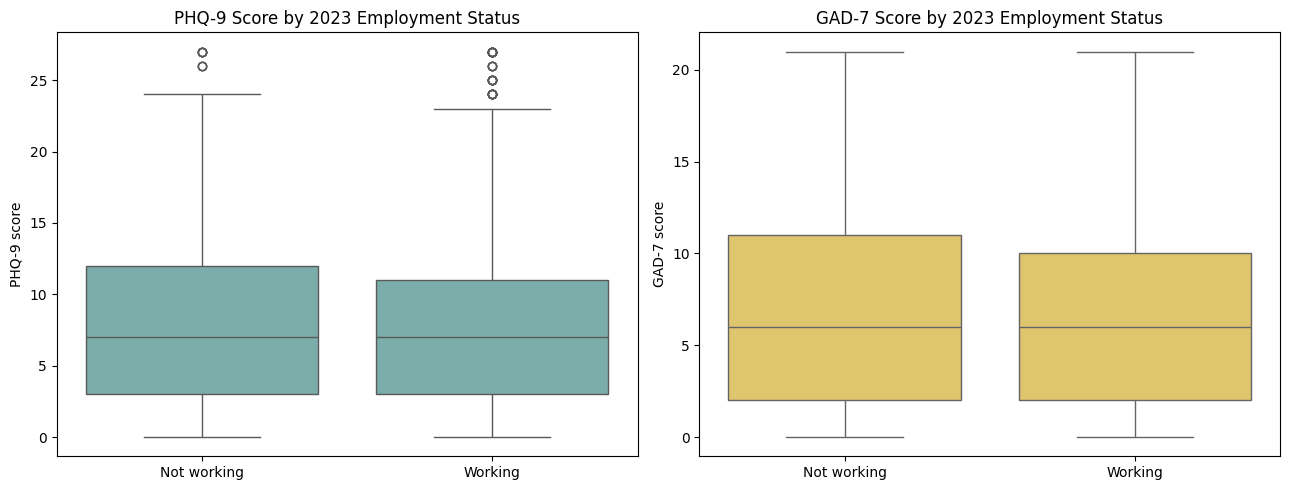

In [47]:
plot_data = model_ready.copy()

plot_data["Employment status"] = (
    plot_data["employed_2023"]
    .map({
        0: "Not working",
        1: "Working"
    })
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)

sns.boxplot(
    data=plot_data,
    x="Employment status",
    y="phq9_score_2021",
    order=["Not working", "Working"],
    color="#72B7B2",
    ax=axes[0]
)

axes[0].set_title("PHQ-9 Score by 2023 Employment Status")
axes[0].set_xlabel("")
axes[0].set_ylabel("PHQ-9 score")


sns.boxplot(
    data=plot_data,
    x="Employment status",
    y="gad7_score_2021",
    order=["Not working", "Working"],
    color="#F2CF5B",
    ax=axes[1]
)

axes[1].set_title("GAD-7 Score by 2023 Employment Status")
axes[1].set_xlabel("")
axes[1].set_ylabel("GAD-7 score")

plt.tight_layout()
plt.show()

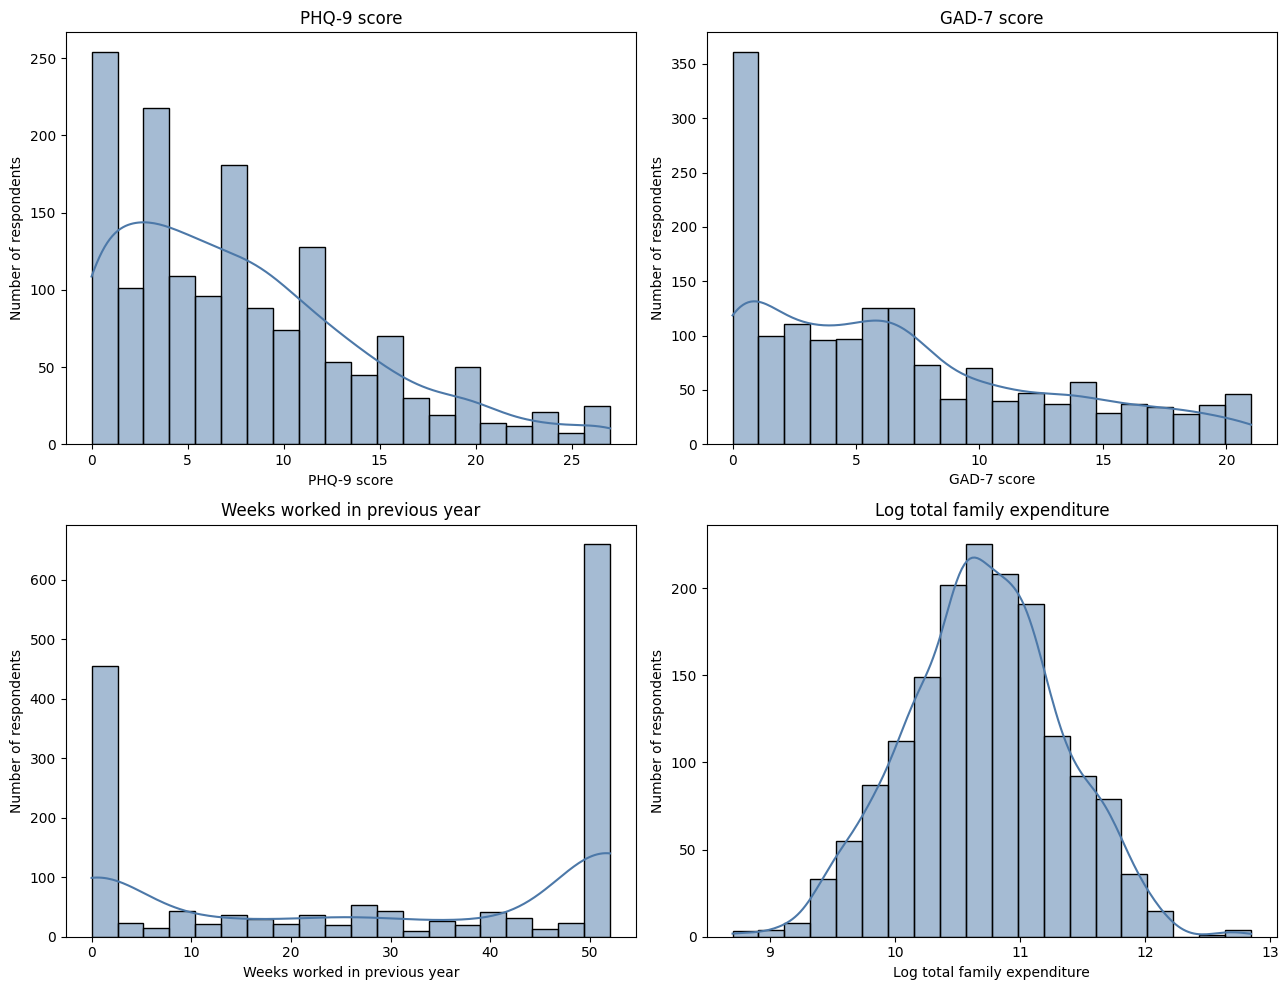

In [48]:
distribution_variables = {
    "phq9_score_2021": "PHQ-9 score",
    "gad7_score_2021": "GAD-7 score",
    "weeks_worked_2020": "Weeks worked in previous year",
    "log_total_expenditure_2021": "Log total family expenditure"
}

fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 10)
)

axes = axes.flatten()

for axis, (variable, label) in zip(
    axes,
    distribution_variables.items()
):

    sns.histplot(
        data=model_ready,
        x=variable,
        bins=20,
        kde=True,
        color="#4C78A8",
        ax=axis
    )

    axis.set_title(label)
    axis.set_xlabel(label)
    axis.set_ylabel("Number of respondents")

plt.tight_layout()
plt.show()

In [49]:
model_ready["phq9_10plus"] = np.where(
    model_ready["phq9_score_2021"].isna(),
    np.nan,
    (model_ready["phq9_score_2021"] >= 10).astype(int)
)

model_ready["gad7_10plus"] = np.where(
    model_ready["gad7_score_2021"].isna(),
    np.nan,
    (model_ready["gad7_score_2021"] >= 10).astype(int)
)

symptom_threshold_table = pd.DataFrame({
    "Measure": [
        "PHQ-9 score ≥ 10",
        "GAD-7 score ≥ 10"
    ],
    "Number meeting threshold": [
        int(model_ready["phq9_10plus"].sum()),
        int(model_ready["gad7_10plus"].sum())
    ],
    "Percent among valid responses": [
        round(model_ready["phq9_10plus"].mean() * 100, 1),
        round(model_ready["gad7_10plus"].mean() * 100, 1)
    ]
})

display(symptom_threshold_table)

,Measure,Number meeting threshold,Percent among valid responses
0,PHQ-9 score ≥ 10,548,34.4
1,GAD-7 score ≥ 10,461,29.0


## 12. Train-Test Split and Logistic Regression

The analytic sample is divided into training and test sets using a stratified
80/20 split. Stratification preserves the proportion working in 2023 in both
sets.

All preprocessing decisions—including missing-value imputation, scaling, and
one-hot encoding—are estimated using the training data only. This prevents
information from the test set from leaking into model training.

In [50]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    confusion_matrix,
    classification_report
)

In [51]:
# Outcome
y = model_ready["employed_2023"].copy()

# Use the same respondents in the test set for all three models
train_indices, test_indices = train_test_split(
    model_ready.index,
    test_size=0.20,
    random_state=42,
    stratify=y
)

y_train = y.loc[train_indices]
y_test = y.loc[test_indices]

split_summary = pd.DataFrame({
    "Sample": ["Training set", "Test set"],
    "Number of respondents": [
        len(y_train),
        len(y_test)
    ],
    "Employment rate": [
        round(y_train.mean() * 100, 1),
        round(y_test.mean() * 100, 1)
    ]
})

display(split_summary)

,Sample,Number of respondents,Employment rate
0,Training set,1295,71.8
1,Test set,324,71.9


In [52]:
all_categorical_features = [
    "employment_status_2021",
    "education_level_2021",
    "enrollment_status_2021"
]


def build_logistic_pipeline(feature_list):

    categorical_features = [
        variable
        for variable in feature_list
        if variable in all_categorical_features
    ]

    numeric_features = [
        variable
        for variable in feature_list
        if variable not in all_categorical_features
    ]

    numeric_pipeline = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(strategy="median")
            ),
            (
                "scaler",
                StandardScaler()
            )
        ]
    )

    categorical_pipeline = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(strategy="most_frequent")
            ),
            (
                "one_hot",
                OneHotEncoder(
                    handle_unknown="ignore",
                    drop="first"
                )
            )
        ]
    )

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                numeric_pipeline,
                numeric_features
            ),
            (
                "categorical",
                categorical_pipeline,
                categorical_features
            )
        ]
    )

    logistic_model = LogisticRegression(
        max_iter=2000,
        random_state=42
    )

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", logistic_model)
        ]
    )

    return pipeline

In [53]:
modeling_data = model_ready.copy()

for variable in all_categorical_features:
    modeling_data[variable] = (
        modeling_data[variable]
        .astype("object")
        .where(
            modeling_data[variable].notna(),
            np.nan
        )
    )

In [54]:
logistic_models = {
    "Model 1: Baseline": {
        "features": model_1_features
    },
    "Model 2: + Education": {
        "features": model_2_features
    },
    "Model 3: + Well-being": {
        "features": model_3_features
    }
}


for model_name, model_information in logistic_models.items():

    features = model_information["features"]

    X_train = modeling_data.loc[
        train_indices,
        features
    ]

    X_test = modeling_data.loc[
        test_indices,
        features
    ]

    pipeline = build_logistic_pipeline(features)

    pipeline.fit(X_train, y_train)

    predicted_probability = pipeline.predict_proba(
        X_test
    )[:, 1]

    predicted_class = (
        predicted_probability >= 0.50
    ).astype(int)

    model_information["pipeline"] = pipeline
    model_information["predicted_probability"] = predicted_probability
    model_information["predicted_class"] = predicted_class

print("All three logistic regression models were fitted.")

All three logistic regression models were fitted.


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [55]:
logistic_results = []

for model_name, model_information in logistic_models.items():

    predicted_probability = (
        model_information["predicted_probability"]
    )

    predicted_class = (
        model_information["predicted_class"]
    )

    logistic_results.append({
        "Model": model_name,

        "ROC AUC": roc_auc_score(
            y_test,
            predicted_probability
        ),

        "PR AUC": average_precision_score(
            y_test,
            predicted_probability
        ),

        "Accuracy": accuracy_score(
            y_test,
            predicted_class
        ),

        "Balanced accuracy": balanced_accuracy_score(
            y_test,
            predicted_class
        ),

        "Log loss": log_loss(
            y_test,
            predicted_probability
        ),

        "Brier score": brier_score_loss(
            y_test,
            predicted_probability
        )
    })


logistic_results = (
    pd.DataFrame(logistic_results)
    .set_index("Model")
    .round(3)
)

display(logistic_results)

,ROC AUC,PR AUC,Accuracy,Balanced accuracy,Log loss,Brier score
Model,,,,,,
Model 1: Baseline,0.717,0.862,0.731,0.572,0.534,0.179
Model 2: + Education,0.741,0.863,0.756,0.616,0.517,0.170
Model 3: + Well-being,0.742,0.869,0.765,0.629,0.514,0.169


Adding education measures improved test-set discrimination, increasing the ROC AUC from 0.717 to 0.741. Adding depressive and anxiety symptom scores produced only a small additional improvement in ROC AUC, from 0.741 to 0.742, although balanced accuracy increased from 0.616 to 0.629.

In [56]:
incremental_results = pd.DataFrame({
    "Comparison": [
        "Education added to baseline",
        "Well-being added to education model"
    ],

    "Change in ROC AUC": [
        logistic_results.loc[
            "Model 2: + Education", "ROC AUC"
        ] - logistic_results.loc[
            "Model 1: Baseline", "ROC AUC"
        ],

        logistic_results.loc[
            "Model 3: + Well-being", "ROC AUC"
        ] - logistic_results.loc[
            "Model 2: + Education", "ROC AUC"
        ]
    ],

    "Change in balanced accuracy": [
        logistic_results.loc[
            "Model 2: + Education", "Balanced accuracy"
        ] - logistic_results.loc[
            "Model 1: Baseline", "Balanced accuracy"
        ],

        logistic_results.loc[
            "Model 3: + Well-being", "Balanced accuracy"
        ] - logistic_results.loc[
            "Model 2: + Education", "Balanced accuracy"
        ]
    ],

    "Change in Brier score": [
        logistic_results.loc[
            "Model 2: + Education", "Brier score"
        ] - logistic_results.loc[
            "Model 1: Baseline", "Brier score"
        ],

        logistic_results.loc[
            "Model 3: + Well-being", "Brier score"
        ] - logistic_results.loc[
            "Model 2: + Education", "Brier score"
        ]
    ]
}).round(3)

display(incremental_results)

,Comparison,Change in ROC AUC,Change in balanced accuracy,Change in Brier score
0,Education added to baseline,0.024,0.044,-0.009
1,Well-being added to education model,0.001,0.013,-0.001


In [57]:
final_logistic = logistic_models[
    "Model 3: + Well-being"
]

final_predictions = final_logistic[
    "predicted_class"
]

confusion = confusion_matrix(
    y_test,
    final_predictions
)

confusion_table = pd.DataFrame(
    confusion,
    index=[
        "Actual: Not working",
        "Actual: Working"
    ],
    columns=[
        "Predicted: Not working",
        "Predicted: Working"
    ]
)

display(confusion_table)

,Predicted: Not working,Predicted: Working
Actual: Not working,29,62
Actual: Working,14,219


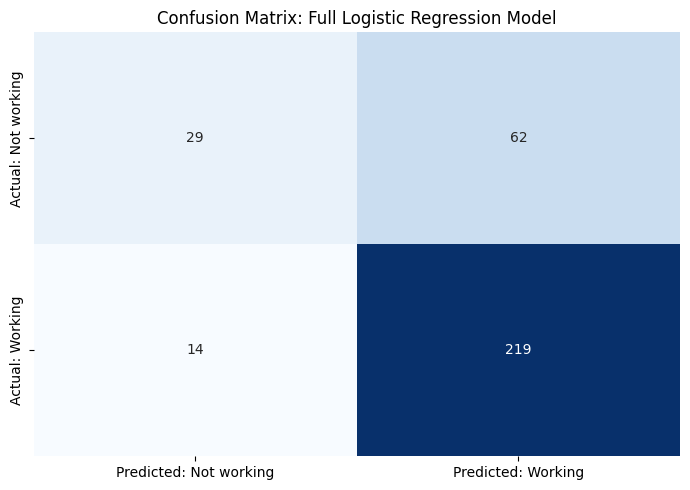

In [58]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    confusion_table,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False
)

plt.title(
    "Confusion Matrix: Full Logistic Regression Model"
)
plt.xlabel("")
plt.ylabel("")

plt.tight_layout()
plt.show()

In [59]:
classification_results = classification_report(
    y_test,
    final_predictions,
    target_names=[
        "Not working",
        "Working"
    ],
    output_dict=True,
    zero_division=0
)

classification_table = (
    pd.DataFrame(classification_results)
    .T
    .round(3)
)

display(classification_table)

,precision,recall,f1-score,support
Not working,0.674,0.319,0.433,91.000
Working,0.779,0.940,0.852,233.000
accuracy,0.765,0.765,0.765,0.765
macro avg,0.727,0.629,0.642,324.000
weighted avg,0.750,0.765,0.734,324.000


### Logistic Regression Coefficients

For continuous predictors, the reported odds ratios correspond to a
one-standard-deviation increase because continuous variables were standardized
within the preprocessing pipeline. For categorical predictors, odds ratios are
interpreted relative to the omitted reference category.

In [60]:
final_pipeline = final_logistic["pipeline"]

preprocessor = final_pipeline.named_steps[
    "preprocessor"
]

logistic_estimator = final_pipeline.named_steps[
    "model"
]

feature_names = (
    preprocessor
    .get_feature_names_out()
)

coefficients = (
    logistic_estimator.coef_[0]
)

coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Odds ratio": np.exp(coefficients)
})

# Make the automatically generated names easier to read
coefficient_table["Feature"] = (
    coefficient_table["Feature"]
    .str.replace("numeric__", "", regex=False)
    .str.replace("categorical__", "", regex=False)
)

coefficient_table["Absolute coefficient"] = (
    coefficient_table["Coefficient"].abs()
)

coefficient_table = (
    coefficient_table
    .sort_values(
        "Absolute coefficient",
        ascending=False
    )
    .drop(columns="Absolute coefficient")
    .reset_index(drop=True)
)

coefficient_table[
    ["Coefficient", "Odds ratio"]
] = coefficient_table[
    ["Coefficient", "Odds ratio"]
].round(3)

display(coefficient_table)

,Feature,Coefficient,Odds ratio
0,employment_status_2021_5,-1.433,0.239
1,employment_status_2021_6,-1.365,0.255
2,enrollment_status_2021_7,1.180,3.256
3,education_level_2021_9,0.993,2.701
4,education_level_2021_11,0.827,2.287
5,employment_status_2021_7,-0.760,0.468
6,employment_status_2021_3,-0.738,0.478
7,employment_status_2021_2,-0.589,0.555
8,enrollment_status_2021_4,0.571,1.770
9,enrollment_status_2021_6,0.534,1.706


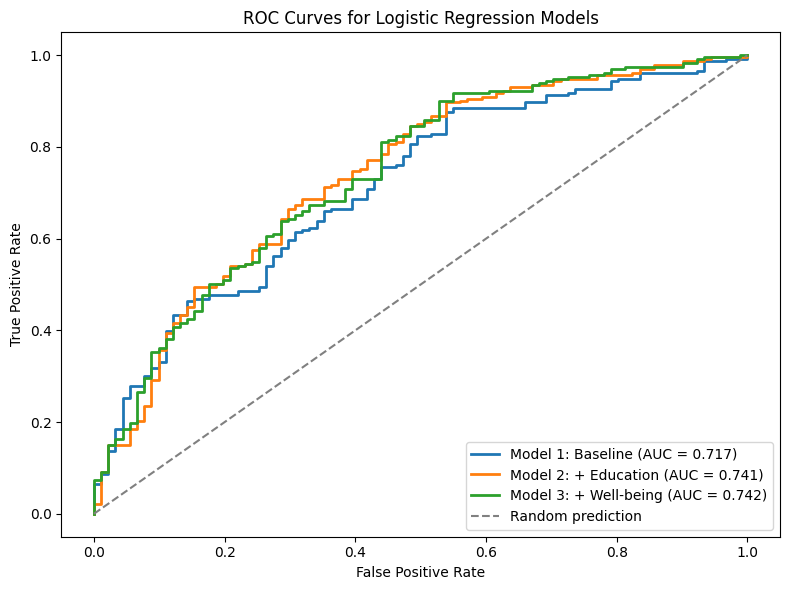

In [61]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 6))

for model_name, model_information in logistic_models.items():

    probabilities = model_information[
        "predicted_probability"
    ]

    false_positive_rate, true_positive_rate, _ = (
        roc_curve(
            y_test,
            probabilities
        )
    )

    auc_value = roc_auc_score(
        y_test,
        probabilities
    )

    plt.plot(
        false_positive_rate,
        true_positive_rate,
        linewidth=2,
        label=f"{model_name} (AUC = {auc_value:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random prediction"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for Logistic Regression Models")
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()

## 13. Correlation and Multicollinearity Assessment

Because depressive and anxiety symptoms frequently co-occur, I examine the
correlation between PHQ-9 and GAD-7 scores. A high correlation does not
necessarily require removing either measure, but it may make their individual
coefficients more difficult to interpret.

In [62]:
wellbeing_correlation = (
    model_ready[
        [
            "phq9_score_2021",
            "gad7_score_2021"
        ]
    ]
    .corr()
    .round(3)
)

display(wellbeing_correlation)

,phq9_score_2021,gad7_score_2021
phq9_score_2021,1.000,0.743
gad7_score_2021,0.743,1.000


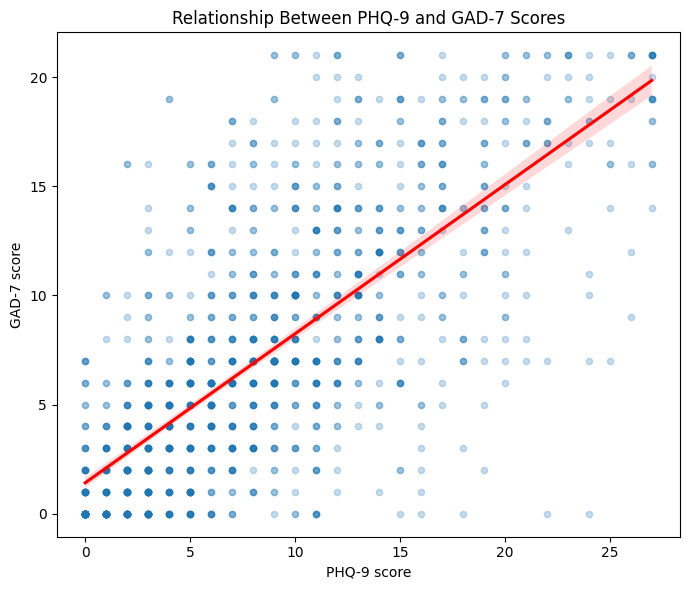

In [63]:
plt.figure(figsize=(7, 6))

sns.regplot(
    data=model_ready,
    x="phq9_score_2021",
    y="gad7_score_2021",
    scatter_kws={
        "alpha": 0.25,
        "s": 20
    },
    line_kws={
        "color": "red"
    }
)

plt.title("Relationship Between PHQ-9 and GAD-7 Scores")
plt.xlabel("PHQ-9 score")
plt.ylabel("GAD-7 score")

plt.tight_layout()
plt.show()

In [64]:
wellbeing_coefficients = coefficient_table[
    coefficient_table["Feature"].isin([
        "phq9_score_2021",
        "gad7_score_2021"
    ])
].copy()

display(wellbeing_coefficients)

,Feature,Coefficient,Odds ratio
22,gad7_score_2021,-0.193,0.825
23,phq9_score_2021,0.182,1.199


In [65]:
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

cross_validation = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring_metrics = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "balanced_accuracy": "balanced_accuracy",
    "log_loss": "neg_log_loss",
    "brier": "neg_brier_score"
}

cross_validation_results = []

for model_name, model_information in logistic_models.items():

    features = model_information["features"]

    X_training_cv = modeling_data.loc[
        train_indices,
        features
    ]

    pipeline = build_logistic_pipeline(features)

    scores = cross_validate(
        pipeline,
        X_training_cv,
        y_train,
        cv=cross_validation,
        scoring=scoring_metrics,
        n_jobs=-1
    )

    cross_validation_results.append({
        "Model": model_name,

        "Mean ROC AUC": scores[
            "test_roc_auc"
        ].mean(),

        "SD ROC AUC": scores[
            "test_roc_auc"
        ].std(),

        "Mean PR AUC": scores[
            "test_pr_auc"
        ].mean(),

        "Mean balanced accuracy": scores[
            "test_balanced_accuracy"
        ].mean(),

        # Negative scoring metrics are converted back
        "Mean log loss": -scores[
            "test_log_loss"
        ].mean(),

        "Mean Brier score": -scores[
            "test_brier"
        ].mean()
    })


cross_validation_results = (
    pd.DataFrame(cross_validation_results)
    .set_index("Model")
    .round(3)
)

display(cross_validation_results)

,Mean ROC AUC,SD ROC AUC,Mean PR AUC,Mean balanced accuracy,Mean log loss,Mean Brier score
Model,,,,,,
Model 1: Baseline,0.721,0.036,0.856,0.593,0.533,0.178
Model 2: + Education,0.734,0.031,0.864,0.604,0.523,0.174
Model 3: + Well-being,0.729,0.036,0.861,0.605,0.526,0.175


In [66]:
wellbeing_model_variants = {
    "PHQ-9 only": (
        baseline_features
        + education_features
        + ["phq9_score_2021"]
    ),

    "GAD-7 only": (
        baseline_features
        + education_features
        + ["gad7_score_2021"]
    ),

    "PHQ-9 and GAD-7": (
        baseline_features
        + education_features
        + [
            "phq9_score_2021",
            "gad7_score_2021"
        ]
    )
}

wellbeing_variant_results = []

for model_name, features in wellbeing_model_variants.items():

    pipeline = build_logistic_pipeline(features)

    X_train_variant = modeling_data.loc[
        train_indices,
        features
    ]

    X_test_variant = modeling_data.loc[
        test_indices,
        features
    ]

    pipeline.fit(
        X_train_variant,
        y_train
    )

    probabilities = pipeline.predict_proba(
        X_test_variant
    )[:, 1]

    wellbeing_variant_results.append({
        "Model": model_name,
        "ROC AUC": roc_auc_score(
            y_test,
            probabilities
        ),
        "PR AUC": average_precision_score(
            y_test,
            probabilities
        ),
        "Brier score": brier_score_loss(
            y_test,
            probabilities
        )
    })

wellbeing_variant_results = (
    pd.DataFrame(wellbeing_variant_results)
    .set_index("Model")
    .round(3)
)

display(wellbeing_variant_results)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,ROC AUC,PR AUC,Brier score
Model,,,
PHQ-9 only,0.741,0.865,0.170
GAD-7 only,0.742,0.865,0.170
PHQ-9 and GAD-7,0.742,0.869,0.169


## 14. XGBoost Model

To assess whether nonlinear relationships and interactions improve prediction,
I estimate an XGBoost classifier using the same training and test samples and
the same predictor set as the full logistic regression model.

Hyperparameters are selected through five-fold cross-validation using the
training sample only. The untouched test sample is then used for final model
evaluation.

In [67]:
!pip -q install xgboost

In [68]:
from xgboost import XGBClassifier

from sklearn.model_selection import RandomizedSearchCV

In [69]:
xgb_numeric_features = [
    variable
    for variable in model_3_features
    if variable not in all_categorical_features
]

xgb_categorical_features = [
    variable
    for variable in model_3_features
    if variable in all_categorical_features
]


xgb_numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)


xgb_categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "one_hot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)


xgb_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            xgb_numeric_pipeline,
            xgb_numeric_features
        ),
        (
            "categorical",
            xgb_categorical_pipeline,
            xgb_categorical_features
        )
    ]
)

In [70]:
xgb_classifier = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=1
)


xgb_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            xgb_preprocessor
        ),
        (
            "model",
            xgb_classifier
        )
    ]
)

In [71]:
xgb_parameter_distributions = {
    "model__n_estimators": [
        100,
        200,
        300,
        500
    ],

    "model__max_depth": [
        2,
        3,
        4,
        5
    ],

    "model__learning_rate": [
        0.01,
        0.03,
        0.05,
        0.10
    ],

    "model__subsample": [
        0.70,
        0.85,
        1.00
    ],

    "model__colsample_bytree": [
        0.70,
        0.85,
        1.00
    ],

    "model__min_child_weight": [
        1,
        3,
        5,
        10
    ],

    "model__reg_alpha": [
        0,
        0.10,
        0.50
    ],

    "model__reg_lambda": [
        1,
        5,
        10
    ]
}

In [72]:
X_train_xgb = modeling_data.loc[
    train_indices,
    model_3_features
]

X_test_xgb = modeling_data.loc[
    test_indices,
    model_3_features
]


xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_parameter_distributions,
    n_iter=30,
    scoring="roc_auc",
    cv=cross_validation,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)


xgb_search.fit(
    X_train_xgb,
    y_train
)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('numeric',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['female',
                                                                                'age_2021',
                                                                                'log_total_expenditure_2021',
                                                                                'weeks_worked_2020',
                                                                                'log_prior_earnings_2020',
                                                                                'prior_earnings_missing',
                                                                                'p...
                   param_distributions={'model__colsample_bytree': [0.7, 0.85,
                                                                    1.0],
                                        'model__learning_rate': [0.01, 0.03,
                                                                 0.05, 0.1],
                                        'model__max_depth': [2, 3, 4, 5],
                                        'model__min_child_weight': [1, 3, 5,
                                                                    10],
                                        'model__n_estimators': [100, 200, 300,
                                                                500],
                                        'model__reg_alpha': [0, 0.1, 0.5],
                                        'model__reg_lambda': [1, 5, 10],
                                        'model__subsample': [0.7, 0.85, 1.0]},
                   random_state=42, return_train_score=True, scoring='roc_auc',
                   verbose=1)

In [73]:
print(
    "Best cross-validated ROC AUC:",
    round(xgb_search.best_score_, 3)
)

print("\nBest parameters:")

for parameter, value in xgb_search.best_params_.items():
    print(parameter, "=", value)

Best cross-validated ROC AUC: 0.727

Best parameters:
model__subsample = 0.7
model__reg_lambda = 1
model__reg_alpha = 0
model__n_estimators = 200
model__min_child_weight = 5
model__max_depth = 2
model__learning_rate = 0.03
model__colsample_bytree = 1.0


In [74]:
best_xgb_model = xgb_search.best_estimator_

xgb_test_probability = (
    best_xgb_model
    .predict_proba(X_test_xgb)[:, 1]
)

xgb_test_prediction = (
    xgb_test_probability >= 0.50
).astype(int)


xgb_test_results = pd.DataFrame({
    "Model": ["XGBoost"],

    "ROC AUC": [
        roc_auc_score(
            y_test,
            xgb_test_probability
        )
    ],

    "PR AUC": [
        average_precision_score(
            y_test,
            xgb_test_probability
        )
    ],

    "Accuracy": [
        accuracy_score(
            y_test,
            xgb_test_prediction
        )
    ],

    "Balanced accuracy": [
        balanced_accuracy_score(
            y_test,
            xgb_test_prediction
        )
    ],

    "Log loss": [
        log_loss(
            y_test,
            xgb_test_probability
        )
    ],

    "Brier score": [
        brier_score_loss(
            y_test,
            xgb_test_probability
        )
    ]
}).set_index("Model").round(3)

display(xgb_test_results)

,ROC AUC,PR AUC,Accuracy,Balanced accuracy,Log loss,Brier score
Model,,,,,,
XGBoost,0.735,0.869,0.725,0.565,0.527,0.177


In [75]:
logistic_full_results = (
    logistic_results
    .loc[["Model 3: + Well-being"]]
    .copy()
)

logistic_full_results.index = [
    "Logistic regression"
]

model_comparison = pd.concat([
    logistic_full_results,
    xgb_test_results
])

display(model_comparison)

,ROC AUC,PR AUC,Accuracy,Balanced accuracy,Log loss,Brier score
Logistic regression,0.742,0.869,0.765,0.629,0.514,0.169
XGBoost,0.735,0.869,0.725,0.565,0.527,0.177


## 15. Permutation Importance

Permutation importance evaluates how much test-set predictive performance
declines when each predictor is randomly shuffled. A larger decrease in ROC AUC
indicates that the fitted model relies more heavily on that predictor.

Importance is evaluated on the held-out test sample. These values describe
predictive contribution and should not be interpreted as causal effects.

In [76]:
from sklearn.inspection import permutation_importance

xgb_permutation = permutation_importance(
    estimator=best_xgb_model,
    X=X_test_xgb,
    y=y_test,
    scoring="roc_auc",
    n_repeats=30,
    random_state=42,
    n_jobs=-1
)

permutation_table = pd.DataFrame({
    "Feature": model_3_features,
    "Mean decrease in ROC AUC":
        xgb_permutation.importances_mean,
    "SD":
        xgb_permutation.importances_std
})

permutation_table = (
    permutation_table
    .sort_values(
        "Mean decrease in ROC AUC",
        ascending=False
    )
    .reset_index(drop=True)
)

permutation_table[
    ["Mean decrease in ROC AUC", "SD"]
] = permutation_table[
    ["Mean decrease in ROC AUC", "SD"]
].round(4)

display(permutation_table)

,Feature,Mean decrease in ROC AUC,SD
0,employment_status_2021,0.0579,0.0207
1,weeks_worked_2020,0.0303,0.0117
2,education_level_2021,0.0186,0.0111
3,log_total_expenditure_2021,0.0167,0.0096
4,prior_earnings_missing,0.0113,0.0037
5,enrollment_status_2021,0.0084,0.0044
6,gad7_score_2021,0.0080,0.0046
7,log_prior_earnings_2020,0.0070,0.0060
8,phq9_score_2021,-0.0001,0.0026
9,female,-0.0002,0.0013


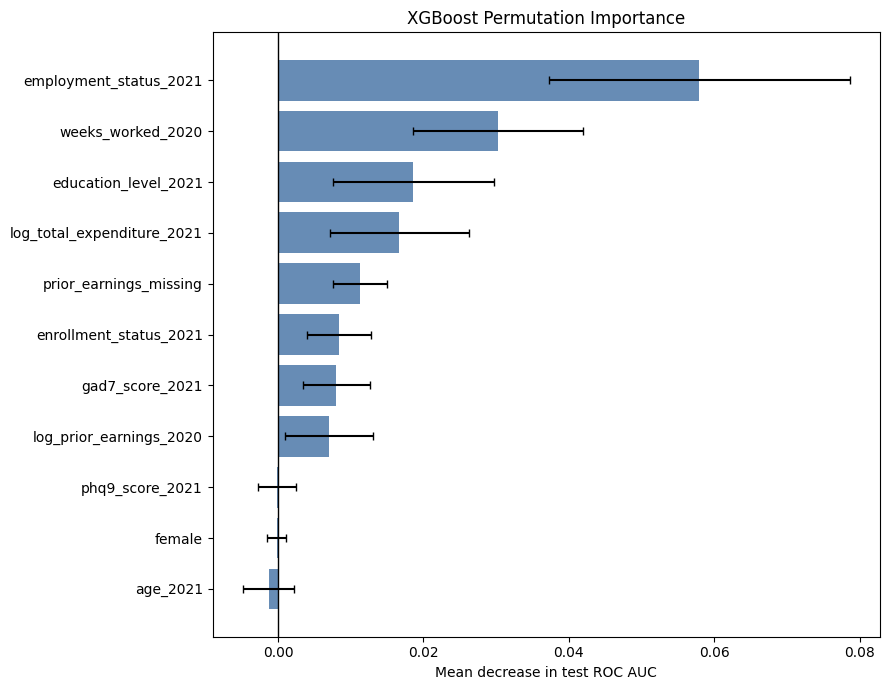

In [77]:
plot_importance = (
    permutation_table
    .sort_values(
        "Mean decrease in ROC AUC",
        ascending=True
    )
)

plt.figure(figsize=(9, 7))

plt.barh(
    plot_importance["Feature"],
    plot_importance["Mean decrease in ROC AUC"],
    xerr=plot_importance["SD"],
    color="#4C78A8",
    alpha=0.85,
    capsize=3
)

plt.axvline(
    x=0,
    color="black",
    linewidth=1
)

plt.xlabel("Mean decrease in test ROC AUC")
plt.ylabel("")
plt.title("XGBoost Permutation Importance")

plt.tight_layout()
plt.show()

In [78]:
!pip -q install shap

In [79]:
import shap
from scipy import sparse

In [80]:
xgb_fitted_preprocessor = (
    best_xgb_model
    .named_steps["preprocessor"]
)

xgb_fitted_estimator = (
    best_xgb_model
    .named_steps["model"]
)

X_test_xgb_transformed = (
    xgb_fitted_preprocessor
    .transform(X_test_xgb)
)

if sparse.issparse(X_test_xgb_transformed):
    X_test_xgb_transformed = (
        X_test_xgb_transformed.toarray()
    )

xgb_feature_names = (
    xgb_fitted_preprocessor
    .get_feature_names_out()
)

xgb_feature_names = [
    name
    .replace("numeric__", "")
    .replace("categorical__", "")
    for name in xgb_feature_names
]

print(
    "Transformed test-data shape:",
    X_test_xgb_transformed.shape
)

print(
    "Number of feature names:",
    len(xgb_feature_names)
)

Transformed test-data shape: (324, 34)
Number of feature names: 34


In [81]:
shap_explainer = shap.TreeExplainer(
    xgb_fitted_estimator
)

shap_values = shap_explainer(
    X_test_xgb_transformed
)

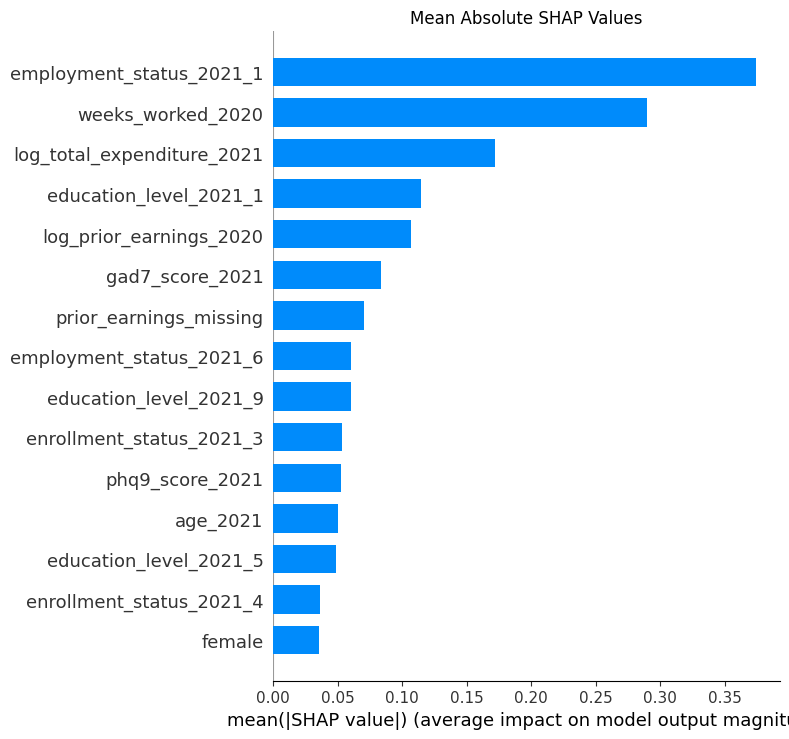

In [82]:
shap.summary_plot(
    shap_values.values,
    X_test_xgb_transformed,
    feature_names=xgb_feature_names,
    plot_type="bar",
    max_display=15,
    show=False
)

plt.title("Mean Absolute SHAP Values")
plt.tight_layout()
plt.show()

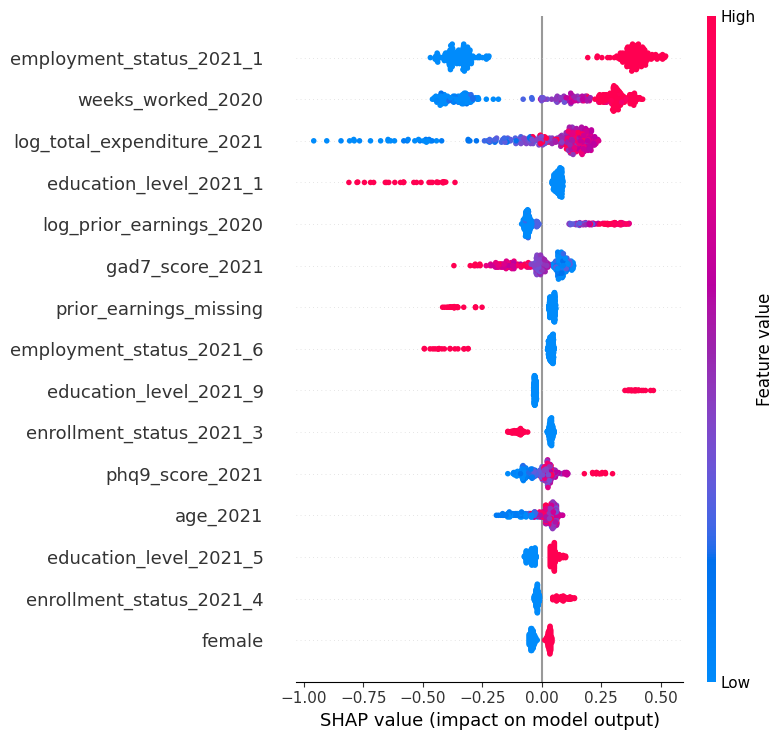

In [83]:
shap.summary_plot(
    shap_values.values,
    X_test_xgb_transformed,
    feature_names=xgb_feature_names,
    max_display=15,
    show=False
)

plt.tight_layout()
plt.show()

## 16. Probability Calibration

Discrimination metrics such as ROC AUC evaluate whether the model correctly
ranks respondents by employment probability. Calibration instead evaluates
whether predicted probabilities correspond to observed employment rates.

I compare the calibration of logistic regression and XGBoost on the held-out
test sample.

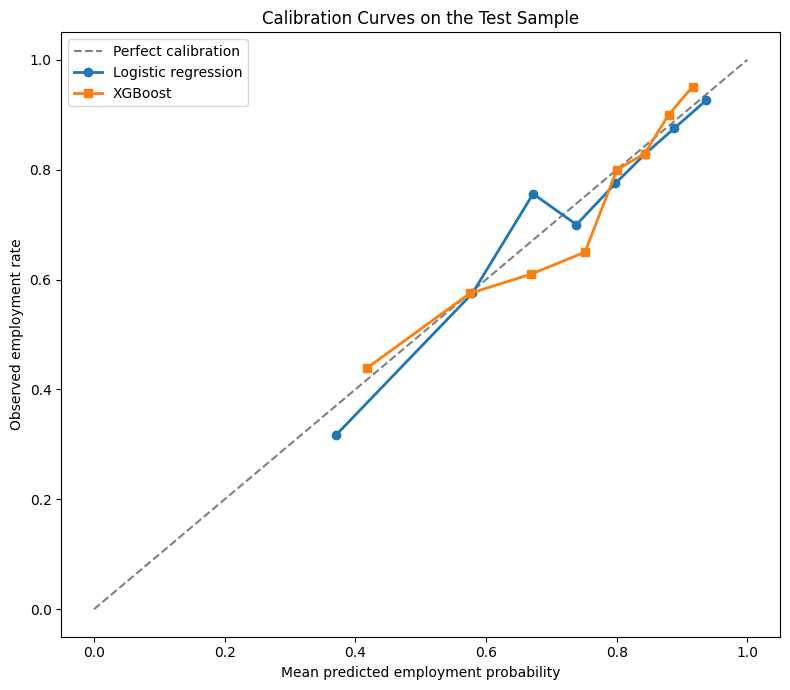

In [84]:
from sklearn.calibration import calibration_curve

logistic_test_probability = logistic_models[
    "Model 3: + Well-being"
]["predicted_probability"]


logistic_observed, logistic_predicted = calibration_curve(
    y_test,
    logistic_test_probability,
    n_bins=8,
    strategy="quantile"
)

xgb_observed, xgb_predicted = calibration_curve(
    y_test,
    xgb_test_probability,
    n_bins=8,
    strategy="quantile"
)


plt.figure(figsize=(8, 7))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect calibration"
)

plt.plot(
    logistic_predicted,
    logistic_observed,
    marker="o",
    linewidth=2,
    label="Logistic regression"
)

plt.plot(
    xgb_predicted,
    xgb_observed,
    marker="s",
    linewidth=2,
    label="XGBoost"
)

plt.xlabel("Mean predicted employment probability")
plt.ylabel("Observed employment rate")
plt.title("Calibration Curves on the Test Sample")
plt.legend()

plt.tight_layout()
plt.show()

In [85]:
logistic_calibration_table = pd.DataFrame({
    "Model": "Logistic regression",
    "Mean predicted probability": logistic_predicted,
    "Observed employment rate": logistic_observed
})

xgb_calibration_table = pd.DataFrame({
    "Model": "XGBoost",
    "Mean predicted probability": xgb_predicted,
    "Observed employment rate": xgb_observed
})

calibration_table = pd.concat(
    [
        logistic_calibration_table,
        xgb_calibration_table
    ],
    ignore_index=True
)

calibration_table[
    [
        "Mean predicted probability",
        "Observed employment rate"
    ]
] = calibration_table[
    [
        "Mean predicted probability",
        "Observed employment rate"
    ]
].round(3)

display(calibration_table)

,Model,Mean predicted probability,Observed employment rate
0,Logistic regression,0.370,0.317
1,Logistic regression,0.579,0.575
2,Logistic regression,0.672,0.756
3,Logistic regression,0.739,0.700
4,Logistic regression,0.798,0.775
5,Logistic regression,0.844,0.829
6,Logistic regression,0.888,0.875
7,Logistic regression,0.937,0.927
8,XGBoost,0.418,0.439
9,XGBoost,0.575,0.575


## 17. Subgroup Evaluation

I evaluate the full logistic regression model separately across sex and age
groups. This analysis examines whether predictive performance differs across
demographic groups.

Subgroup differences are descriptive because the test sample is relatively
small, and they should not be interpreted as definitive evidence of algorithmic
bias.

In [86]:
subgroup_test = modeling_data.loc[
    test_indices,
    [
        "female",
        "age_2021"
    ]
].copy()

subgroup_test["actual"] = y_test

subgroup_test["predicted_probability"] = (
    logistic_test_probability
)

subgroup_test["predicted_class"] = (
    logistic_test_probability >= 0.50
).astype(int)

subgroup_test["sex_group"] = (
    subgroup_test["female"]
    .map({
        0: "Male",
        1: "Female"
    })
)

subgroup_test["age_group"] = np.where(
    subgroup_test["age_2021"] <= 21,
    "Age 17–21",
    "Age 22–26"
)

In [87]:
def evaluate_subgroups(data, group_variable):

    results = []

    for group_name, group_data in data.groupby(
        group_variable
    ):

        actual = group_data["actual"]
        probability = group_data[
            "predicted_probability"
        ]
        predicted = group_data[
            "predicted_class"
        ]

        if actual.nunique() == 2:
            subgroup_auc = roc_auc_score(
                actual,
                probability
            )
        else:
            subgroup_auc = np.nan

        results.append({
            "Group": group_name,
            "N": len(group_data),
            "Observed employment rate":
                actual.mean(),
            "Mean predicted probability":
                probability.mean(),
            "ROC AUC": subgroup_auc,
            "Accuracy": accuracy_score(
                actual,
                predicted
            ),
            "Balanced accuracy":
                balanced_accuracy_score(
                    actual,
                    predicted
                ),
            "Brier score": brier_score_loss(
                actual,
                probability
            )
        })

    results = pd.DataFrame(results)

    percentage_columns = [
        "Observed employment rate",
        "Mean predicted probability"
    ]

    results[percentage_columns] = (
        results[percentage_columns] * 100
    )

    numeric_columns = [
        "Observed employment rate",
        "Mean predicted probability",
        "ROC AUC",
        "Accuracy",
        "Balanced accuracy",
        "Brier score"
    ]

    results[numeric_columns] = (
        results[numeric_columns].round(3)
    )

    return results

In [88]:
sex_subgroup_results = evaluate_subgroups(
    subgroup_test,
    "sex_group"
)

display(sex_subgroup_results)

,Group,N,Observed employment rate,Mean predicted probability,ROC AUC,Accuracy,Balanced accuracy,Brier score
0,Female,171,71.345,74.274,0.771,0.784,0.653,0.16
1,Male,153,72.549,71.196,0.708,0.745,0.602,0.18


In [89]:
age_subgroup_results = evaluate_subgroups(
    subgroup_test,
    "age_group"
)

display(age_subgroup_results)

,Group,N,Observed employment rate,Mean predicted probability,ROC AUC,Accuracy,Balanced accuracy,Brier score
0,Age 17–21,162,68.519,68.657,0.750,0.741,0.636,0.178
1,Age 22–26,162,75.309,76.984,0.731,0.790,0.617,0.160


## 18. Decision-Threshold Analysis

The default probability threshold of 0.50 prioritizes overall accuracy but
identifies relatively few respondents who are not working. Because a policy
screening tool may place greater value on identifying individuals at risk of
nonemployment, I evaluate alternative thresholds.

The threshold is selected using out-of-fold predictions from the training
sample only. The selected threshold is then evaluated on the held-out test
sample.

In [90]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import recall_score, precision_score

threshold_model_features = model_3_features

threshold_pipeline = build_logistic_pipeline(
    threshold_model_features
)

X_train_threshold = modeling_data.loc[
    train_indices,
    threshold_model_features
]

X_test_threshold = modeling_data.loc[
    test_indices,
    threshold_model_features
]


training_oof_probability = cross_val_predict(
    estimator=threshold_pipeline,
    X=X_train_threshold,
    y=y_train,
    cv=cross_validation,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

In [91]:
threshold_values = np.arange(
    0.30,
    0.86,
    0.01
)

threshold_results = []

for threshold in threshold_values:

    prediction = (
        training_oof_probability >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,

        "Accuracy": accuracy_score(
            y_train,
            prediction
        ),

        "Balanced accuracy":
            balanced_accuracy_score(
                y_train,
                prediction
            ),

        "Recall: Not working":
            recall_score(
                y_train,
                prediction,
                pos_label=0
            ),

        "Recall: Working":
            recall_score(
                y_train,
                prediction,
                pos_label=1
            ),

        "Precision: Not working":
            precision_score(
                y_train,
                prediction,
                pos_label=0,
                zero_division=0
            )
    })


threshold_results = pd.DataFrame(
    threshold_results
)

display(
    threshold_results
    .sort_values(
        "Balanced accuracy",
        ascending=False
    )
    .head(10)
    .round(3)
)

,Threshold,Accuracy,Balanced accuracy,Recall: Not working,Recall: Working,Precision: Not working
44,0.74,0.658,0.679,0.726,0.631,0.436
43,0.73,0.665,0.678,0.707,0.648,0.441
42,0.72,0.669,0.672,0.677,0.667,0.443
33,0.63,0.732,0.669,0.523,0.814,0.525
45,0.75,0.641,0.668,0.732,0.605,0.421
38,0.68,0.694,0.668,0.608,0.728,0.467
37,0.67,0.700,0.667,0.592,0.742,0.474
40,0.70,0.678,0.667,0.641,0.692,0.450
39,0.69,0.685,0.667,0.625,0.709,0.457
36,0.66,0.707,0.666,0.570,0.761,0.484


In [92]:
best_threshold_row = threshold_results.loc[
    threshold_results[
        "Balanced accuracy"
    ].idxmax()
]

selected_threshold = best_threshold_row[
    "Threshold"
]

print(
    "Selected threshold:",
    round(selected_threshold, 2)
)

display(
    best_threshold_row
    .to_frame(name="Training performance")
    .round(3)
)

Selected threshold: 0.74


,Training performance
Threshold,0.740
Accuracy,0.658
Balanced accuracy,0.679
Recall: Not working,0.726
Recall: Working,0.631
Precision: Not working,0.436


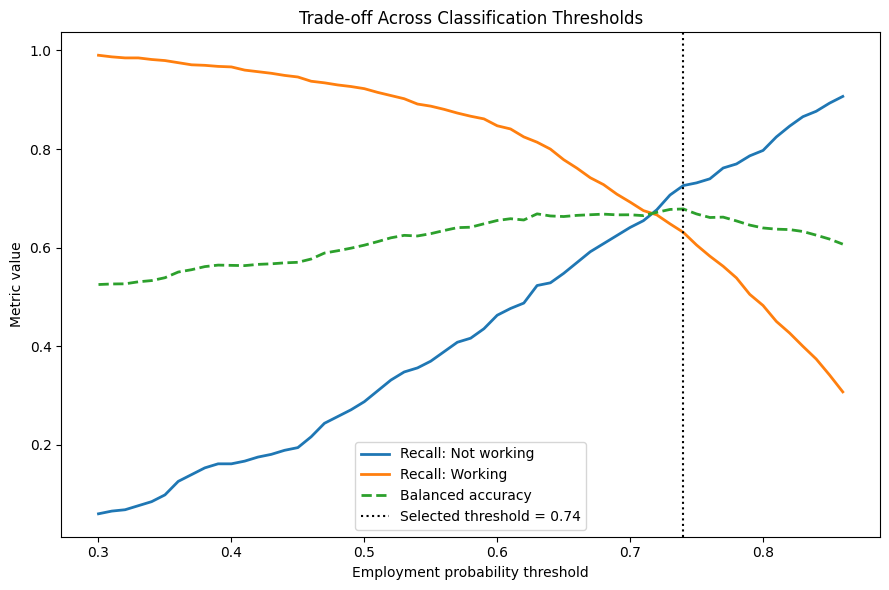

In [93]:
plt.figure(figsize=(9, 6))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall: Not working"],
    label="Recall: Not working",
    linewidth=2
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall: Working"],
    label="Recall: Working",
    linewidth=2
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Balanced accuracy"],
    label="Balanced accuracy",
    linewidth=2,
    linestyle="--"
)

plt.axvline(
    selected_threshold,
    color="black",
    linestyle=":",
    label=(
        "Selected threshold = "
        f"{selected_threshold:.2f}"
    )
)

plt.xlabel("Employment probability threshold")
plt.ylabel("Metric value")
plt.title("Trade-off Across Classification Thresholds")
plt.legend()

plt.tight_layout()
plt.show()

In [94]:
threshold_pipeline.fit(
    X_train_threshold,
    y_train
)

test_probability_threshold_model = (
    threshold_pipeline
    .predict_proba(X_test_threshold)[:, 1]
)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [95]:
test_threshold_comparison = []

for threshold_name, threshold in {
    "Default threshold (0.50)": 0.50,
    "Training-selected threshold":
        selected_threshold
}.items():

    prediction = (
        test_probability_threshold_model
        >= threshold
    ).astype(int)

    test_threshold_comparison.append({
        "Threshold rule": threshold_name,
        "Threshold": threshold,

        "Accuracy": accuracy_score(
            y_test,
            prediction
        ),

        "Balanced accuracy":
            balanced_accuracy_score(
                y_test,
                prediction
            ),

        "Recall: Not working":
            recall_score(
                y_test,
                prediction,
                pos_label=0
            ),

        "Recall: Working":
            recall_score(
                y_test,
                prediction,
                pos_label=1
            ),

        "Precision: Not working":
            precision_score(
                y_test,
                prediction,
                pos_label=0,
                zero_division=0
            )
    })


test_threshold_comparison = (
    pd.DataFrame(test_threshold_comparison)
    .set_index("Threshold rule")
    .round(3)
)

display(test_threshold_comparison)

,Threshold,Accuracy,Balanced accuracy,Recall: Not working,Recall: Working,Precision: Not working
Threshold rule,,,,,,
Default threshold (0.50),0.50,0.765,0.629,0.319,0.940,0.674
Training-selected threshold,0.74,0.660,0.670,0.692,0.648,0.434


In [96]:
selected_threshold_prediction = (
    test_probability_threshold_model
    >= selected_threshold
).astype(int)

selected_confusion = confusion_matrix(
    y_test,
    selected_threshold_prediction
)

selected_confusion_table = pd.DataFrame(
    selected_confusion,
    index=[
        "Actual: Not working",
        "Actual: Working"
    ],
    columns=[
        "Predicted: Not working",
        "Predicted: Working"
    ]
)

display(selected_confusion_table)

,Predicted: Not working,Predicted: Working
Actual: Not working,63,28
Actual: Working,82,151


## 19. Robustness and Sensitivity Analyses

I conduct two sensitivity analyses. First, I compare the primary imputation-
based model with a complete-case model among respondents with no missing
predictors. Second, I repeat the train-test split across multiple random seeds
to assess whether the incremental predictive contribution of education and
well-being is stable.

In [97]:
# Identify respondents with complete values on all Model 3 predictors
complete_case_mask = (
    modeling_data[model_3_features]
    .notna()
    .all(axis=1)
)

complete_train_indices = [
    index
    for index in train_indices
    if complete_case_mask.loc[index]
]

complete_test_indices = [
    index
    for index in test_indices
    if complete_case_mask.loc[index]
]

print(
    "Complete training cases:",
    len(complete_train_indices)
)

print(
    "Complete test cases:",
    len(complete_test_indices)
)

Complete training cases: 1112
Complete test cases: 286


In [98]:
complete_case_pipeline = build_logistic_pipeline(
    model_3_features
)

complete_case_pipeline.fit(
    modeling_data.loc[
        complete_train_indices,
        model_3_features
    ],
    y.loc[complete_train_indices]
)

complete_case_probability = (
    complete_case_pipeline
    .predict_proba(
        modeling_data.loc[
            complete_test_indices,
            model_3_features
        ]
    )[:, 1]
)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [99]:
main_probability_series = pd.Series(
    logistic_test_probability,
    index=test_indices
)

imputed_probability_complete_subset = (
    main_probability_series
    .loc[complete_test_indices]
    .values
)

complete_test_outcome = y.loc[
    complete_test_indices
]

In [100]:
complete_case_comparison = []

for model_name, probability in {
    "Imputation model": (
        imputed_probability_complete_subset
    ),
    "Complete-case model": (
        complete_case_probability
    )
}.items():

    prediction = (
        probability >= 0.50
    ).astype(int)

    complete_case_comparison.append({
        "Model": model_name,

        "Test N": len(
            complete_test_outcome
        ),

        "ROC AUC": roc_auc_score(
            complete_test_outcome,
            probability
        ),

        "PR AUC": average_precision_score(
            complete_test_outcome,
            probability
        ),

        "Accuracy": accuracy_score(
            complete_test_outcome,
            prediction
        ),

        "Balanced accuracy":
            balanced_accuracy_score(
                complete_test_outcome,
                prediction
            ),

        "Brier score": brier_score_loss(
            complete_test_outcome,
            probability
        )
    })


complete_case_comparison = (
    pd.DataFrame(complete_case_comparison)
    .set_index("Model")
    .round(3)
)

display(complete_case_comparison)

,Test N,ROC AUC,PR AUC,Accuracy,Balanced accuracy,Brier score
Model,,,,,,
Imputation model,286,0.750,0.876,0.79,0.651,0.161
Complete-case model,286,0.751,0.877,0.78,0.632,0.161


In [101]:
repeated_split_results = []

for split_seed in range(30):

    repeated_train_indices, repeated_test_indices = (
        train_test_split(
            modeling_data.index,
            test_size=0.20,
            random_state=split_seed,
            stratify=y
        )
    )

    repeated_y_train = y.loc[
        repeated_train_indices
    ]

    repeated_y_test = y.loc[
        repeated_test_indices
    ]

    repeated_model_definitions = {
        "Education model": model_2_features,
        "Education + well-being model":
            model_3_features
    }

    for model_name, features in (
        repeated_model_definitions.items()
    ):

        repeated_pipeline = (
            build_logistic_pipeline(features)
        )

        repeated_pipeline.fit(
            modeling_data.loc[
                repeated_train_indices,
                features
            ],
            repeated_y_train
        )

        repeated_probability = (
            repeated_pipeline
            .predict_proba(
                modeling_data.loc[
                    repeated_test_indices,
                    features
                ]
            )[:, 1]
        )

        repeated_split_results.append({
            "Seed": split_seed,
            "Model": model_name,

            "ROC AUC": roc_auc_score(
                repeated_y_test,
                repeated_probability
            ),

            "PR AUC": average_precision_score(
                repeated_y_test,
                repeated_probability
            ),

            "Brier score": brier_score_loss(
                repeated_y_test,
                repeated_probability
            )
        })


repeated_split_results = pd.DataFrame(
    repeated_split_results
)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categ

In [102]:
repeated_summary = (
    repeated_split_results
    .groupby("Model")
    .agg({
        "ROC AUC": [
            "mean",
            "std",
            "min",
            "max"
        ],
        "PR AUC": [
            "mean",
            "std"
        ],
        "Brier score": [
            "mean",
            "std"
        ]
    })
    .round(3)
)

display(repeated_summary)

ROC AUC                      PR AUC         \
                                mean    std    min    max   mean    std   
Model                                                                     
Education + well-being model   0.728  0.033  0.643  0.778  0.861  0.020   
Education model                0.729  0.034  0.641  0.777  0.859  0.021   

                             Brier score        
                                    mean   std  
Model                                           
Education + well-being model       0.175  0.01  
Education model                    0.175  0.01

In [103]:
repeated_auc_wide = (
    repeated_split_results
    .pivot(
        index="Seed",
        columns="Model",
        values="ROC AUC"
    )
)

repeated_auc_wide[
    "Well-being improvement"
] = (
    repeated_auc_wide[
        "Education + well-being model"
    ]
    - repeated_auc_wide[
        "Education model"
    ]
)

display(
    repeated_auc_wide
    .round(3)
)

print(
    "Mean change in ROC AUC:",
    round(
        repeated_auc_wide[
            "Well-being improvement"
        ].mean(),
        3
    )
)

print(
    "Number of splits improved:",
    (
        repeated_auc_wide[
            "Well-being improvement"
        ] > 0
    ).sum(),
    "out of",
    len(repeated_auc_wide)
)

Model,Education + well-being model,Education model,Well-being improvement
Seed,,,
0,0.754,0.750,0.004
1,0.744,0.741,0.003
2,0.695,0.691,0.005
3,0.758,0.758,-0.000
4,0.726,0.724,0.002
5,0.693,0.695,-0.002
6,0.762,0.762,0.000
7,0.643,0.641,0.002
8,0.747,0.742,0.005


Mean change in ROC AUC: -0.001
Number of splits improved: 14 out of 30


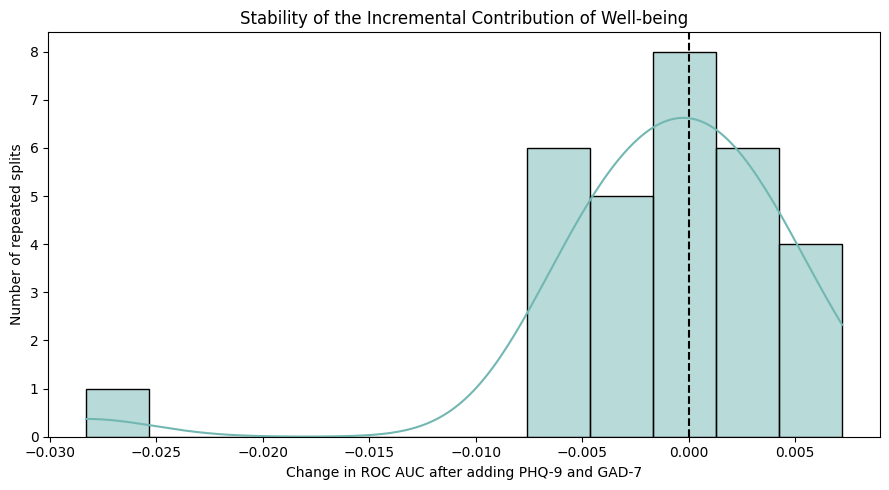

In [104]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=repeated_auc_wide,
    x="Well-being improvement",
    bins=12,
    kde=True,
    color="#72B7B2"
)

plt.axvline(
    0,
    color="black",
    linestyle="--"
)

plt.xlabel(
    "Change in ROC AUC after adding PHQ-9 and GAD-7"
)

plt.ylabel("Number of repeated splits")

plt.title(
    "Stability of the Incremental Contribution of Well-being"
)

plt.tight_layout()
plt.show()

In [105]:
employment_status_labels = {
    1: "Working now, including military",
    2: "Temporarily laid off, sick, or maternity leave",
    3: "Looking for work or unemployed",
    4: "Retired",
    5: "Disabled",
    6: "Keeping house",
    7: "Student",
    8: "Other",
}

enrollment_status_labels = {
    1: "No high school diploma or GED",
    2: "GED, no high school diploma",
    3: "High school diploma",
    4: "Not enrolled, some college",
    5: "Not enrolled, associate degree",
    6: "Not enrolled, bachelor's degree",
    7: "Not enrolled, graduate degree",
    9: "Enrolled, no prior degree",
    10: "Enrolled, prior degree",
    11: "Enrolled in graduate program",
}

education_level_labels = {
    1: "Less than high school",
    2: "GED, no college",
    3: "High school graduate, no college",
    4: "GED plus some college",
    5: "High school graduate plus some college",
    6: "GED plus associate degree",
    7: "High school graduate plus associate degree",
    8: "GED plus bachelor's degree",
    9: "High school graduate plus bachelor's degree",
    10: "GED plus master's degree",
    11: "High school graduate plus master's degree",
    12: "GED plus doctoral degree",
    13: "High school graduate plus doctoral degree",
    14: "GED plus medical degree",
    15: "High school graduate plus medical degree",
    16: "GED plus law degree",
    17: "High school graduate plus law degree",
    18: "GED plus other degree",
    19: "High school graduate plus other degree",
}

category_label_maps = {
    "employment_status_2021": employment_status_labels,
    "enrollment_status_2021": enrollment_status_labels,
    "education_level_2021": education_level_labels,
}


def make_feature_readable(feature):
    """Convert names such as education_level_2021_9 into readable labels."""
    for variable, label_map in category_label_maps.items():
        prefix = variable + "_"

        if feature.startswith(prefix):
            raw_code = feature[len(prefix):]

            try:
                code = int(float(raw_code))
            except ValueError:
                return feature

            label = label_map.get(code, f"Code {code}")
            return f"{variable}: {label}"

    continuous_labels = {
        "weeks_worked_2020": "Weeks worked in 2020",
        "log_total_expenditure_2021": "Log total family expenditure",
        "log_prior_earnings_2020": "Log prior earnings",
        "prior_earnings_missing": "Prior earnings missing",
        "phq9_score_2021": "PHQ-9 score",
        "gad7_score_2021": "GAD-7 score",
        "age_2021": "Age",
        "female": "Female",
    }

    return continuous_labels.get(feature, feature)


# Create a readable coefficient table
coefficient_table_readable = coefficient_table.copy()
coefficient_table_readable["Feature label"] = (
    coefficient_table_readable["Feature"]
    .apply(make_feature_readable)
)

display(
    coefficient_table_readable[
        ["Feature label", "Coefficient", "Odds ratio"]
    ]
)

,Feature label,Coefficient,Odds ratio
0,employment_status_2021: Disabled,-1.433,0.239
1,employment_status_2021: Keeping house,-1.365,0.255
2,"enrollment_status_2021: Not enrolled, graduate...",1.180,3.256
3,education_level_2021: High school graduate plu...,0.993,2.701
4,education_level_2021: High school graduate plu...,0.827,2.287
5,employment_status_2021: Student,-0.760,0.468
6,employment_status_2021: Looking for work or un...,-0.738,0.478
7,"employment_status_2021: Temporarily laid off, ...",-0.589,0.555
8,"enrollment_status_2021: Not enrolled, some col...",0.571,1.770
9,"enrollment_status_2021: Not enrolled, bachelor...",0.534,1.706


In [106]:
from sklearn.base import clone
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

# Refit both models using the original training split
education_model = build_logistic_pipeline(model_2_features)
full_model = build_logistic_pipeline(model_3_features)

education_model.fit(
    modeling_data.loc[train_indices, model_2_features],
    y.loc[train_indices]
)

full_model.fit(
    modeling_data.loc[train_indices, model_3_features],
    y.loc[train_indices]
)

# Predictions on exactly the same test respondents
y_test_bootstrap = y.loc[test_indices].to_numpy()

education_probability = education_model.predict_proba(
    modeling_data.loc[test_indices, model_2_features]
)[:, 1]

full_probability = full_model.predict_proba(
    modeling_data.loc[test_indices, model_3_features]
)[:, 1]


# Point estimates
incremental_point_estimates = pd.DataFrame({
    "Metric": [
        "ROC AUC",
        "PR AUC",
        "Brier score"
    ],
    "Education model": [
        roc_auc_score(
            y_test_bootstrap,
            education_probability
        ),
        average_precision_score(
            y_test_bootstrap,
            education_probability
        ),
        brier_score_loss(
            y_test_bootstrap,
            education_probability
        )
    ],
    "Education + well-being model": [
        roc_auc_score(
            y_test_bootstrap,
            full_probability
        ),
        average_precision_score(
            y_test_bootstrap,
            full_probability
        ),
        brier_score_loss(
            y_test_bootstrap,
            full_probability
        )
    ]
})

incremental_point_estimates["Change after adding well-being"] = [
    incremental_point_estimates.loc[0, "Education + well-being model"]
    - incremental_point_estimates.loc[0, "Education model"],

    incremental_point_estimates.loc[1, "Education + well-being model"]
    - incremental_point_estimates.loc[1, "Education model"],

    incremental_point_estimates.loc[2, "Education model"]
    - incremental_point_estimates.loc[2, "Education + well-being model"]
    # Positive means an improvement because a lower Brier score is better
]

display(incremental_point_estimates.round(4))


# Paired bootstrap confidence intervals
random_generator = np.random.default_rng(42)
number_of_bootstraps = 5000
number_of_test_cases = len(y_test_bootstrap)

bootstrap_results = []

for bootstrap_number in range(number_of_bootstraps):
    sampled_positions = random_generator.integers(
        0,
        number_of_test_cases,
        size=number_of_test_cases
    )

    sampled_y = y_test_bootstrap[sampled_positions]

    # ROC AUC cannot be calculated if only one outcome class is sampled
    if np.unique(sampled_y).size < 2:
        continue

    sampled_education_probability = (
        education_probability[sampled_positions]
    )
    sampled_full_probability = (
        full_probability[sampled_positions]
    )

    education_roc = roc_auc_score(
        sampled_y,
        sampled_education_probability
    )
    full_roc = roc_auc_score(
        sampled_y,
        sampled_full_probability
    )

    education_pr = average_precision_score(
        sampled_y,
        sampled_education_probability
    )
    full_pr = average_precision_score(
        sampled_y,
        sampled_full_probability
    )

    education_brier = brier_score_loss(
        sampled_y,
        sampled_education_probability
    )
    full_brier = brier_score_loss(
        sampled_y,
        sampled_full_probability
    )

    bootstrap_results.append({
        "ROC AUC change": full_roc - education_roc,
        "PR AUC change": full_pr - education_pr,

        # Positive values indicate improvement
        "Brier score improvement":
            education_brier - full_brier
    })


bootstrap_results = pd.DataFrame(bootstrap_results)

bootstrap_summary = pd.DataFrame([
    {
        "Metric": metric,
        "Mean change": bootstrap_results[metric].mean(),
        "95% CI lower": bootstrap_results[metric].quantile(0.025),
        "95% CI upper": bootstrap_results[metric].quantile(0.975),
        "Percent improved": (
            bootstrap_results[metric] > 0
        ).mean() * 100
    }
    for metric in bootstrap_results.columns
]).round(4)

display(bootstrap_summary)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,Metric,Education model,Education + well-being model,Change after adding well-being
0,ROC AUC,0.7415,0.7419,0.0005
1,PR AUC,0.8628,0.8691,0.0063
2,Brier score,0.1699,0.1692,0.0007


,Metric,Mean change,95% CI lower,95% CI upper,Percent improved
0,ROC AUC change,0.0005,-0.0117,0.0118,53.48
1,PR AUC change,0.0058,-0.0035,0.0170,86.60
2,Brier score improvement,0.0007,-0.0019,0.0032,70.50
